## <span style="color:#1F4E79;">Optimization of the Bradley–Terry Likelihood</span>

This notebook compares different methods for fitting the Bradley–Terry model. We first use handcrafted optimizers and then reproduce the experiments using PyTorch. Every method is tested on the same simulated dataset.

In [1]:
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from bradley_terry import *
import bradley_terry.pytorch_optimization as bt_torch

##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Centres the parameters so that their mean is zero. |
| `generate_uniform_comparison_data()` | Simulates `(winner, loser)` observations. |
| `average_negative_log_likelihood()` | Calculates the average NLL on the complete dataset. |
| `parameter_recovery_error()` | Calculates RMSE between the true and estimated parameters. |
| `ford_condition_holds()` | Checks whether a finite Bradley–Terry MLE exists. |
| `optimize_with_full_batch_gradient_descent()` | Updates the parameters using the complete dataset. |
| `optimize_with_stochastic_gradient_descent()` | Updates the parameters using one observation at a time. |
| `optimize_with_minibatch_gradient_descent()` | Updates the parameters using small batches of observations. |
| `optimize_with_momentum_gradient_descent()` | Applies momentum to mini-batch gradient descent. |
| `optimize_with_adam()` | Uses Adam's adaptive first- and second-moment updates. |
| `OptimizationResult` | Stores the fitted parameters, optimization history and runtime. |

In [2]:
# Define settings shared by every optimizer.

SEED = 20260831
NUMBER_OF_ITEMS = 10
NUMBER_OF_COMPARISONS = 10_000
MINIBATCH_SIZE = 128
GRADIENT_TOLERANCE = 1e-6

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

experiment_settings = pd.DataFrame({
    "Setting": [
        "Random seed",
        "Number of items",
        "Number of comparisons",
        "Mini-batch size",
        "Full-gradient tolerance",
    ],
    "Value": [
        str(SEED),
        str(NUMBER_OF_ITEMS),
        f"{NUMBER_OF_COMPARISONS:,}",
        str(MINIBATCH_SIZE),
        f"{GRADIENT_TOLERANCE:.1e}",
    ],
})

experiment_settings

,Setting,Value
0,Random seed,20260831
1,Number of items,10
2,Number of comparisons,"10,000"
3,Mini-batch size,128
4,Full-gradient tolerance,1.0e-06


### Common Dataset
We generate one Bradley–Terry dataset and keep it fixed throughout the notebook. Every optimizer therefore receives the same observations and starts from the same zero parameter vector.

In [3]:
# Generate one fixed dataset for all optimization experiments.

item_names = [
    f"Item {item_index}"
    for item_index in range(NUMBER_OF_ITEMS)
]

true_parameters = center_parameters(
    rng.normal(
        loc=0.0,
        scale=0.8,
        size=NUMBER_OF_ITEMS,
    )
)

comparisons = generate_uniform_comparison_data(
    true_parameters=true_parameters,
    number_of_comparisons=NUMBER_OF_COMPARISONS,
    rng=rng,
)

true_parameter_table = pd.DataFrame({
    "Item": item_names,
    "True parameter": true_parameters,
})

print(f"Number of observations: {len(comparisons):,}")
print(f"First five observations: {comparisons[:5]}")
print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

true_parameter_table.style.format({
    "True parameter": "{:.4f}",
})

Number of observations: 10,000
First five observations: [(1, 4), (8, 9), (0, 8), (0, 4), (3, 7)]
Ford's condition holds: True


,Item,True parameter
0,Item 0,0.0499
1,Item 1,0.0969
2,Item 2,0.4827
3,Item 3,1.5604
4,Item 4,-0.3540
5,Item 5,-1.1734
6,Item 6,-0.1724
7,Item 7,0.0065
8,Item 8,-0.5966
9,Item 9,0.0999


In [4]:
# Summarize item appearances and verify Ford's condition.

comparison_array = np.asarray(
    comparisons,
    dtype=int,
)

wins = np.bincount(
    comparison_array[:, 0],
    minlength=NUMBER_OF_ITEMS,
)

losses = np.bincount(
    comparison_array[:, 1],
    minlength=NUMBER_OF_ITEMS,
)

appearances = wins + losses
empirical_win_rates = wins / appearances

comparison_summary_table = pd.DataFrame({
    "item": item_names,
    "true_parameter": true_parameters,
    "wins": wins,
    "losses": losses,
    "appearances": appearances,
    "empirical_win_rate": empirical_win_rates,
})

print(
    "Ford's condition holds:",
    ford_condition_holds(
        NUMBER_OF_ITEMS,
        comparisons,
    ),
)

comparison_summary_table

Ford's condition holds: True


,item,true_parameter,wins,losses,appearances,empirical_win_rate
0,Item 0,0.0499,1033,958,1991,0.5188
1,Item 1,0.0969,1028,927,1955,0.5258
2,Item 2,0.4827,1267,793,2060,0.6150
3,Item 3,1.5604,1702,309,2011,0.8463
4,Item 4,-0.3540,838,1133,1971,0.4252
5,Item 5,-1.1734,467,1567,2034,0.2296
6,Item 6,-0.1724,869,1093,1962,0.4429
7,Item 7,0.0065,1038,934,1972,0.5264
8,Item 8,-0.5966,712,1309,2021,0.3523
9,Item 9,0.0999,1046,977,2023,0.5171


### Experiment 1: Handcrafted Full-Batch Gradient Descent

In [5]:
# Fit the model using convergence-driven handcrafted full-batch GD.

full_batch_learning_rate = 0.1

full_batch_result = optimize_with_full_batch_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=full_batch_learning_rate,
    gradient_tolerance=GRADIENT_TOLERANCE,
)

full_batch_recovery_error = parameter_recovery_error(
    true_parameters,
    full_batch_result.parameters,
)

final_gradient_norm = float(
    full_batch_result.gradient_norm_history[-1]
)

full_batch_converged = (
    final_gradient_norm <= GRADIENT_TOLERANCE
)

full_batch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Gradient tolerance",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Final gradient norm",
        "Converged",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{full_batch_learning_rate:.4f}",
        f"{GRADIENT_TOLERANCE:.4e}",
        f"{full_batch_result.nll_history[0]:.4f}",
        f"{full_batch_result.nll_history[-1]:.4f}",
        f"{full_batch_recovery_error:.4f}",
        f"{full_batch_result.epochs_completed:,}",
        f"{int(full_batch_result.update_count_history[-1]):,}",
        f"{final_gradient_norm:.4e}",
        str(full_batch_converged),
        full_batch_result.stopping_reason,
        f"{full_batch_result.runtime_seconds:.4f}",
        f"{full_batch_result.parameters.sum():.4e}",
    ],
})

full_batch_summary

,Quantity,Value
0,Learning rate,0.1000
1,Gradient tolerance,1.0000e-06
2,Initial NLL,0.6931
3,Final NLL,0.5982
4,Parameter-recovery RMSE,0.0383
5,Epochs completed,"3,706"
6,Parameter updates,"3,706"
7,Final gradient norm,9.9908e-07
8,Converged,True
9,Stopping reason,gradient tolerance reached


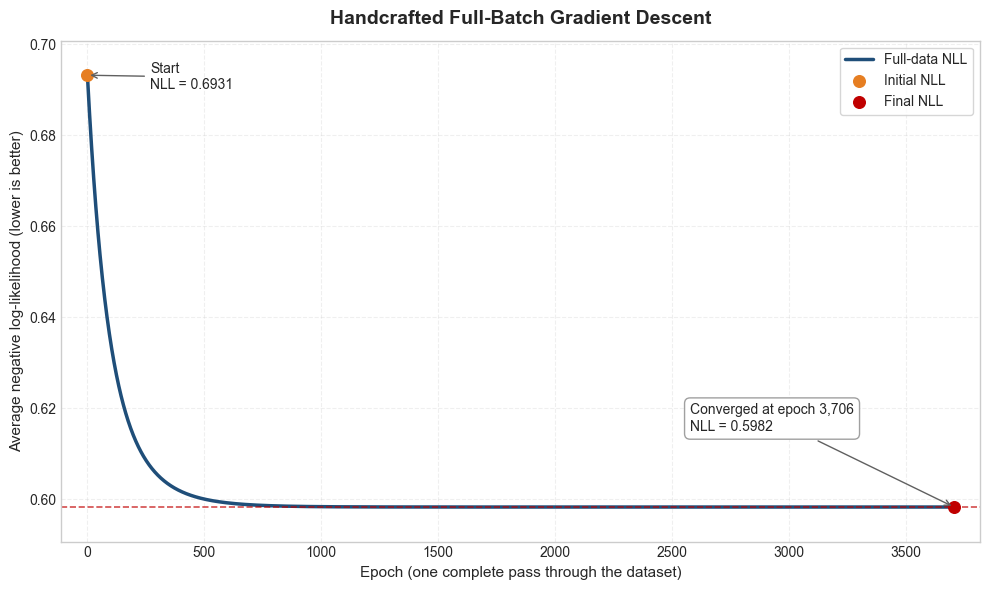

In [6]:
# Plot the full-data NLL during handcrafted full-batch optimization.

full_batch_nll_history = np.asarray(
    full_batch_result.nll_history,
    dtype=float,
)

full_batch_epochs = np.arange(
    len(full_batch_nll_history)
)

initial_nll = full_batch_nll_history[0]
final_nll = full_batch_nll_history[-1]
stopping_epoch = full_batch_result.epochs_completed

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    full_batch_epochs,
    full_batch_nll_history,
    color="#1F4E79",
    linewidth=2.5,
    label="Full-data NLL",
)

axis.scatter(
    0,
    initial_nll,
    color="#E67E22",
    s=70,
    zorder=3,
    label="Initial NLL",
)

axis.scatter(
    stopping_epoch,
    final_nll,
    color="#C00000",
    s=70,
    zorder=3,
    label="Final NLL",
)

axis.axhline(
    final_nll,
    color="#C00000",
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
)

axis.annotate(
    f"Start\nNLL = {initial_nll:.4f}",
    xy=(0, initial_nll),
    xytext=(45, -10),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
)

axis.annotate(
    (
        f"Converged at epoch {stopping_epoch:,}\n"
        f"NLL = {final_nll:.4f}"
    ),
    xy=(stopping_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average negative log-likelihood (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Handcrafted Full-Batch Gradient Descent",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.03, y=0.08)

plt.tight_layout()
plt.show()

#### Convergence check
To show that the gradient norm is falling below the selected gradient tolerance and has converged.

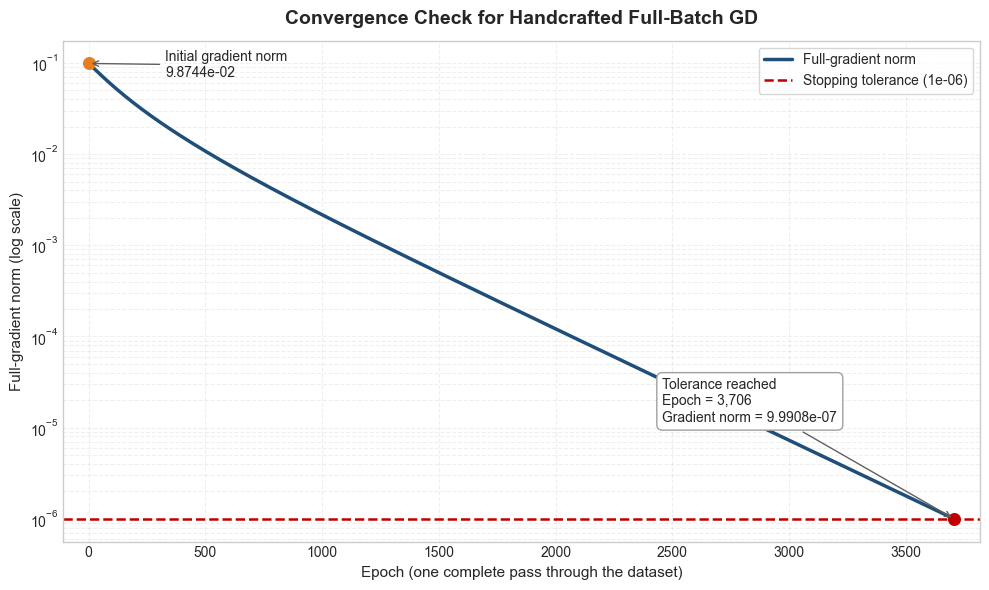

In [7]:
# Plot the full-gradient norm and the stopping tolerance.

gradient_norm_history = np.asarray(
    full_batch_result.gradient_norm_history,
    dtype=float,
)

gradient_epochs = np.arange(
    len(gradient_norm_history)
)

initial_gradient_norm = gradient_norm_history[0]
final_gradient_norm = gradient_norm_history[-1]
stopping_epoch = full_batch_result.epochs_completed

figure, axis = plt.subplots(figsize=(10, 6))

axis.semilogy(
    gradient_epochs,
    gradient_norm_history,
    color="#1F4E79",
    linewidth=2.5,
    label="Full-gradient norm",
)

axis.axhline(
    y=GRADIENT_TOLERANCE,
    color="#C00000",
    linestyle="--",
    linewidth=1.8,
    label=(
        "Stopping tolerance "
        f"({GRADIENT_TOLERANCE:.0e})"
    ),
)

axis.scatter(
    0,
    initial_gradient_norm,
    color="#E67E22",
    s=70,
    zorder=3,
)

axis.scatter(
    stopping_epoch,
    final_gradient_norm,
    color="#C00000",
    s=70,
    zorder=3,
)

axis.annotate(
    (
        f"Initial gradient norm\n"
        f"{initial_gradient_norm:.4e}"
    ),
    xy=(0, initial_gradient_norm),
    xytext=(55, -10),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
)

axis.annotate(
    (
        f"Tolerance reached\n"
        f"Epoch = {stopping_epoch:,}\n"
        f"Gradient norm = {final_gradient_norm:.4e}"
    ),
    xy=(stopping_epoch, final_gradient_norm),
    xytext=(-210, 70),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Full-gradient norm (log scale)",
    fontsize=11,
)

axis.set_title(
    "Convergence Check for Handcrafted Full-Batch GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.03)

plt.tight_layout()
plt.show()

### Experiment 2: Handcrafted Stochastic Gradient Descent


In [8]:
# Fit the model using convergence-driven handcrafted SGD.

sgd_learning_rate = 0.001
NLL_TARGET_MARGIN = 1e-4

reference_nll = float(
    full_batch_result.nll_history[-1]
)

target_nll = (
    reference_nll
    + NLL_TARGET_MARGIN
)

sgd_result = optimize_with_stochastic_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=sgd_learning_rate,
    random_seed=SEED,
    target_nll=target_nll,
)

sgd_recovery_error = parameter_recovery_error(
    true_parameters,
    sgd_result.parameters,
)

sgd_final_nll = float(
    sgd_result.nll_history[-1]
)

sgd_target_reached = (
    sgd_final_nll <= target_nll
)

sgd_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Reference full-batch NLL",
        "Allowed NLL margin",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{sgd_learning_rate:.4f}",
        f"{reference_nll:.4f}",
        f"{NLL_TARGET_MARGIN:.4e}",
        f"{target_nll:.4f}",
        f"{sgd_result.nll_history[0]:.4f}",
        f"{sgd_final_nll:.4f}",
        f"{sgd_recovery_error:.4f}",
        f"{sgd_result.epochs_completed:,}",
        f"{int(sgd_result.update_count_history[-1]):,}",
        str(sgd_target_reached),
        sgd_result.stopping_reason,
        f"{sgd_result.runtime_seconds:.4f}",
        f"{sgd_result.parameters.sum():.4e}",
    ],
})

sgd_summary

,Quantity,Value
0,Learning rate,0.0010
1,Reference full-batch NLL,0.5982
2,Allowed NLL margin,1.0000e-04
3,Target NLL,0.5983
4,Initial NLL,0.6931
5,Final NLL,0.5983
6,Parameter-recovery RMSE,0.0440
7,Epochs completed,10
8,Parameter updates,"100,000"
9,Target reached,True


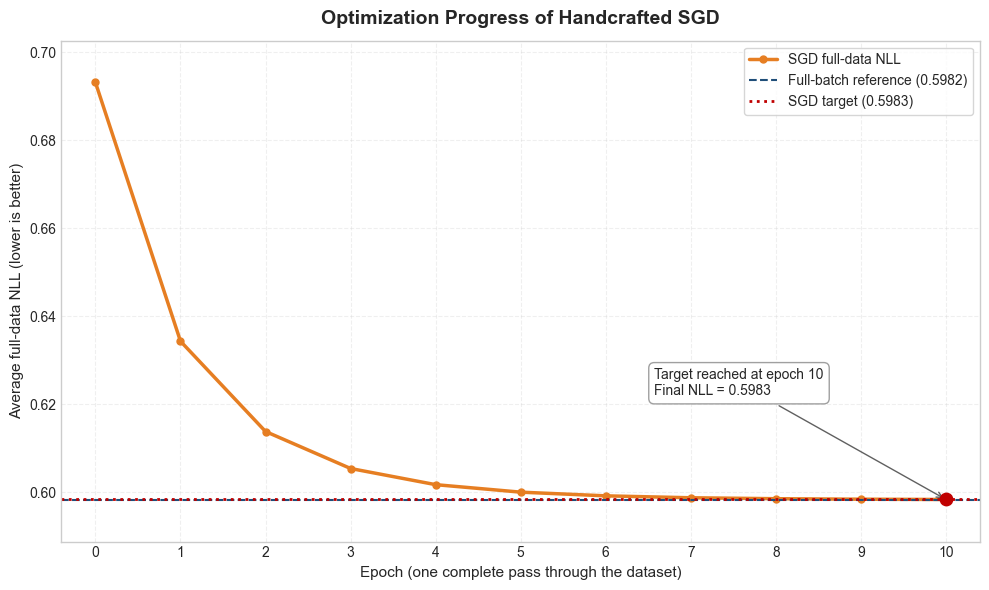

In [9]:
# Plot the full-data NLL during handcrafted SGD.

sgd_nll_history = np.asarray(
    sgd_result.nll_history,
    dtype=float,
)

sgd_epochs = np.arange(
    len(sgd_nll_history)
)

sgd_final_epoch = sgd_result.epochs_completed
sgd_final_nll = sgd_nll_history[-1]

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    sgd_epochs,
    sgd_nll_history,
    color="#E67E22",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="SGD full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"SGD target ({target_nll:.4f})",
)

axis.scatter(
    sgd_final_epoch,
    sgd_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch {sgd_final_epoch}\n"
        f"Final NLL = {sgd_final_nll:.4f}"
    ),
    xy=(sgd_final_epoch, sgd_final_nll),
    xytext=(-210, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted SGD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.set_xticks(sgd_epochs)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

The full-data NLL is measured after every epoch. The dashed lines above shows the accurate full-batch result and the target that SGD must reach.



### Experiment 3: Handcrafted Mini-Batch Gradient Descent


In [10]:
# Fit the model using convergence-driven mini-batch gradient descent.

minibatch_learning_rate = 0.01

minibatch_result = optimize_with_minibatch_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=minibatch_learning_rate,
    batch_size=MINIBATCH_SIZE,
    random_seed=SEED,
    target_nll=target_nll,
)

minibatch_recovery_error = parameter_recovery_error(
    true_parameters,
    minibatch_result.parameters,
)

minibatch_final_nll = float(
    minibatch_result.nll_history[-1]
)

minibatch_target_reached = (
    minibatch_final_nll <= target_nll
)

batches_per_epoch = int(
    np.ceil(
        NUMBER_OF_COMPARISONS
        / MINIBATCH_SIZE
    )
)

minibatch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{minibatch_learning_rate:.4f}",
        str(MINIBATCH_SIZE),
        str(batches_per_epoch),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{minibatch_result.nll_history[0]:.4f}",
        f"{minibatch_final_nll:.4f}",
        f"{minibatch_recovery_error:.4f}",
        f"{minibatch_result.epochs_completed:,}",
        f"{int(minibatch_result.update_count_history[-1]):,}",
        str(minibatch_target_reached),
        minibatch_result.stopping_reason,
        f"{minibatch_result.runtime_seconds:.4f}",
        f"{minibatch_result.parameters.sum():.4e}",
    ],
})

minibatch_summary

,Quantity,Value
0,Learning rate,0.0100
1,Mini-batch size,128
2,Batches per epoch,79
3,Reference full-batch NLL,0.5982
4,Target NLL,0.5983
5,Initial NLL,0.6931
6,Final NLL,0.5983
7,Parameter-recovery RMSE,0.0439
8,Epochs completed,122
9,Parameter updates,"9,638"


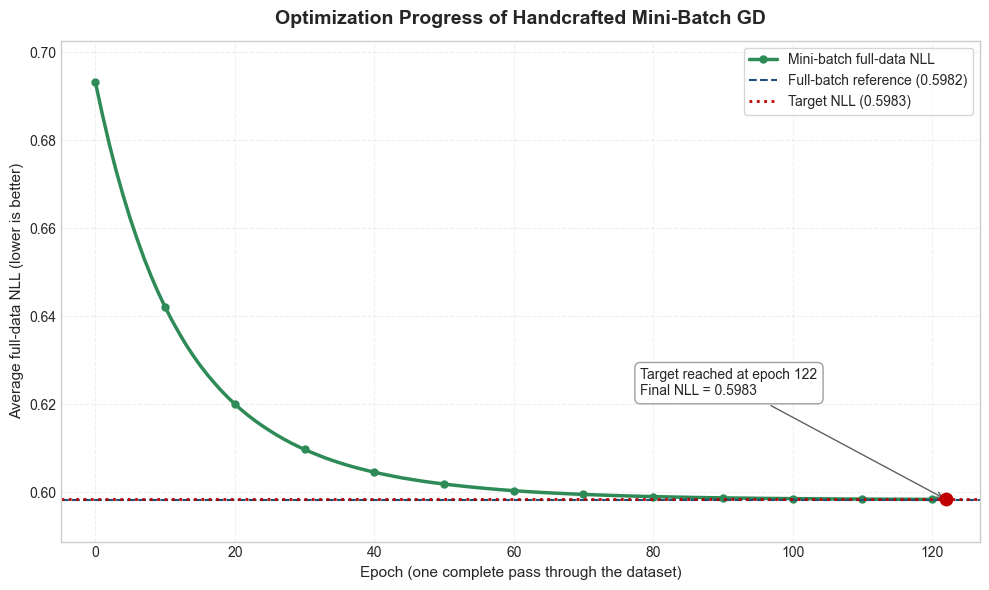

In [11]:
# Plot the full-data NLL during mini-batch optimization.

minibatch_nll_history = np.asarray(
    minibatch_result.nll_history,
    dtype=float,
)

minibatch_epochs = np.arange(
    len(minibatch_nll_history)
)

minibatch_final_epoch = (
    minibatch_result.epochs_completed
)

minibatch_final_nll = (
    minibatch_nll_history[-1]
)

marker_spacing = max(
    1,
    len(minibatch_epochs) // 12,
)

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    minibatch_epochs,
    minibatch_nll_history,
    color="#2E8B57",
    linewidth=2.5,
    marker="o",
    markersize=5,
    markevery=marker_spacing,
    label="Mini-batch full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

axis.scatter(
    minibatch_final_epoch,
    minibatch_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch "
        f"{minibatch_final_epoch:,}\n"
        f"Final NLL = {minibatch_final_nll:.4f}"
    ),
    xy=(
        minibatch_final_epoch,
        minibatch_final_nll,
    ),
    xytext=(-220, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted Mini-Batch GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 4: Handcrafted Momentum Gradient Descent


In [12]:
# Fit the model using convergence-driven momentum gradient descent.

momentum_learning_rate = minibatch_learning_rate
momentum_coefficient = 0.9

momentum_result = optimize_with_momentum_gradient_descent(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=momentum_learning_rate,
    batch_size=MINIBATCH_SIZE,
    momentum=momentum_coefficient,
    random_seed=SEED,
    target_nll=target_nll,
)

momentum_recovery_error = parameter_recovery_error(
    true_parameters,
    momentum_result.parameters,
)

momentum_final_nll = float(
    momentum_result.nll_history[-1]
)

momentum_target_reached = (
    momentum_final_nll <= target_nll
)

momentum_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Momentum coefficient",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{momentum_learning_rate:.4f}",
        f"{momentum_coefficient:.4f}",
        str(MINIBATCH_SIZE),
        str(batches_per_epoch),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{momentum_result.nll_history[0]:.4f}",
        f"{momentum_final_nll:.4f}",
        f"{momentum_recovery_error:.4f}",
        f"{momentum_result.epochs_completed:,}",
        f"{int(momentum_result.update_count_history[-1]):,}",
        str(momentum_target_reached),
        momentum_result.stopping_reason,
        f"{momentum_result.runtime_seconds:.4f}",
        f"{momentum_result.parameters.sum():.4e}",
    ],
})

momentum_summary

,Quantity,Value
0,Learning rate,0.0100
1,Momentum coefficient,0.9000
2,Mini-batch size,128
3,Batches per epoch,79
4,Reference full-batch NLL,0.5982
5,Target NLL,0.5983
6,Initial NLL,0.6931
7,Final NLL,0.5983
8,Parameter-recovery RMSE,0.0463
9,Epochs completed,12


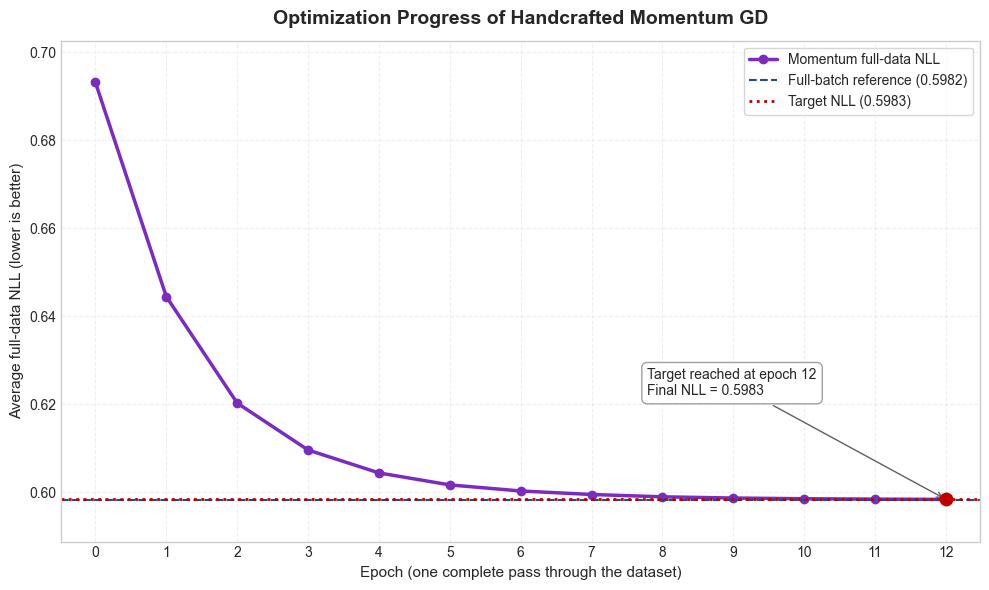

In [13]:
# Plot the full-data NLL during momentum optimization.

momentum_nll_history = np.asarray(
    momentum_result.nll_history,
    dtype=float,
)

momentum_epochs = np.arange(
    len(momentum_nll_history)
)

momentum_final_epoch = (
    momentum_result.epochs_completed
)

momentum_final_nll = (
    momentum_nll_history[-1]
)

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    momentum_epochs,
    momentum_nll_history,
    color="#7B2CBF",
    linewidth=2.5,
    marker="o",
    markersize=6,
    label="Momentum full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

axis.scatter(
    momentum_final_epoch,
    momentum_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch "
        f"{momentum_final_epoch:,}\n"
        f"Final NLL = {momentum_final_nll:.4f}"
    ),
    xy=(
        momentum_final_epoch,
        momentum_final_nll,
    ),
    xytext=(-215, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted Momentum GD",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.set_xticks(momentum_epochs)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 5: Handcrafted Adam


In [14]:
# Fit the model using convergence-driven handcrafted Adam.

adam_learning_rate = 0.01
adam_beta_1 = 0.9
adam_beta_2 = 0.999
adam_epsilon = 1e-8

adam_result = optimize_with_adam(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=adam_learning_rate,
    batch_size=MINIBATCH_SIZE,
    beta_1=adam_beta_1,
    beta_2=adam_beta_2,
    epsilon=adam_epsilon,
    random_seed=SEED,
    target_nll=target_nll,
)

adam_recovery_error = parameter_recovery_error(
    true_parameters,
    adam_result.parameters,
)

adam_final_nll = float(
    adam_result.nll_history[-1]
)

adam_target_reached = (
    adam_final_nll <= target_nll
)

adam_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Beta 1",
        "Beta 2",
        "Epsilon",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{adam_learning_rate:.4f}",
        f"{adam_beta_1:.4f}",
        f"{adam_beta_2:.4f}",
        f"{adam_epsilon:.4e}",
        str(MINIBATCH_SIZE),
        str(batches_per_epoch),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{adam_result.nll_history[0]:.4f}",
        f"{adam_final_nll:.4f}",
        f"{adam_recovery_error:.4f}",
        f"{adam_result.epochs_completed:,}",
        f"{int(adam_result.update_count_history[-1]):,}",
        str(adam_target_reached),
        adam_result.stopping_reason,
        f"{adam_result.runtime_seconds:.4f}",
        f"{adam_result.parameters.sum():.4e}",
    ],
})

adam_summary

,Quantity,Value
0,Learning rate,0.0100
1,Beta 1,0.9000
2,Beta 2,0.9990
3,Epsilon,1.0000e-08
4,Mini-batch size,128
5,Batches per epoch,79
6,Reference full-batch NLL,0.5982
7,Target NLL,0.5983
8,Initial NLL,0.6931
9,Final NLL,0.5983


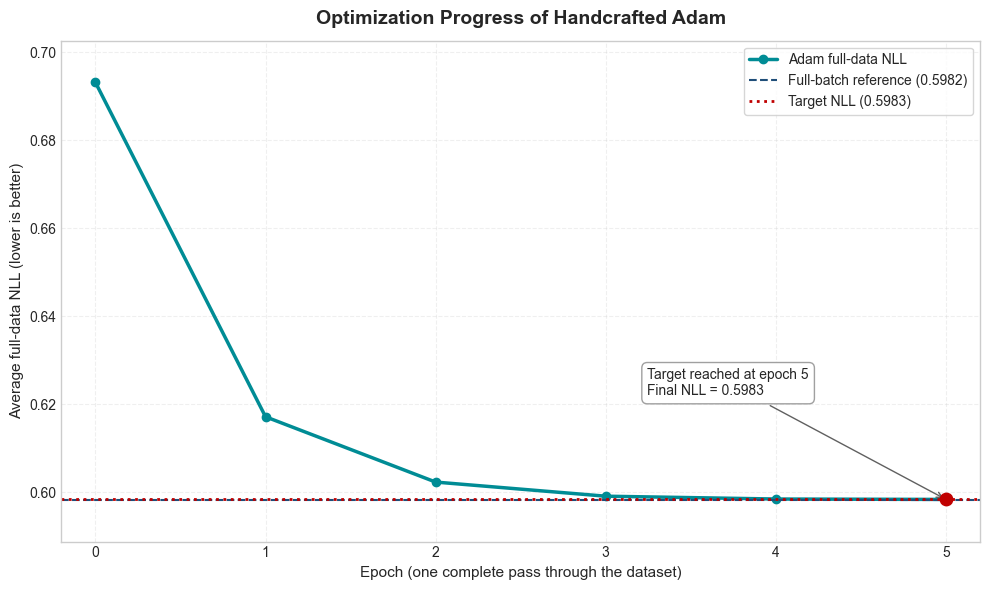

In [15]:
# Plot the full-data NLL during Adam optimization.

adam_nll_history = np.asarray(
    adam_result.nll_history,
    dtype=float,
)

adam_epochs = np.arange(
    len(adam_nll_history)
)

adam_final_epoch = adam_result.epochs_completed
adam_final_nll = adam_nll_history[-1]

marker_spacing = max(
    1,
    len(adam_epochs) // 12,
)

figure, axis = plt.subplots(figsize=(10, 6))

axis.plot(
    adam_epochs,
    adam_nll_history,
    color="#008C95",
    linewidth=2.5,
    marker="o",
    markersize=6,
    markevery=marker_spacing,
    label="Adam full-data NLL",
)

axis.axhline(
    y=reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.5,
    label=f"Full-batch reference ({reference_nll:.4f})",
)

axis.axhline(
    y=target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

axis.scatter(
    adam_final_epoch,
    adam_final_nll,
    color="#C00000",
    s=80,
    zorder=4,
)

axis.annotate(
    (
        f"Target reached at epoch "
        f"{adam_final_epoch:,}\n"
        f"Final NLL = {adam_final_nll:.4f}"
    ),
    xy=(
        adam_final_epoch,
        adam_final_nll,
    ),
    xytext=(-215, 75),
    textcoords="offset points",
    arrowprops={
        "arrowstyle": "->",
        "color": "#606060",
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#A0A0A0",
    },
)

axis.set_xlabel(
    "Epoch (one complete pass through the dataset)",
    fontsize=11,
)

axis.set_ylabel(
    "Average full-data NLL (lower is better)",
    fontsize=11,
)

axis.set_title(
    "Optimization Progress of Handcrafted Adam",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.legend(
    frameon=True,
    loc="upper right",
)

axis.grid(
    True,
    linestyle="--",
    alpha=0.3,
)

axis.margins(x=0.04, y=0.1)

plt.tight_layout()
plt.show()

### Comparison of Handcrafted Optimizers


In [16]:
# Run full-batch GD using the common target for a fair comparison.

full_batch_target_result = (
    optimize_with_full_batch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=full_batch_learning_rate,
        target_nll=target_nll,
    )
)

handcrafted_result_details = [
    (
        "Full-batch GD",
        full_batch_target_result,
        NUMBER_OF_COMPARISONS,
    ),
    (
        "SGD",
        sgd_result,
        1,
    ),
    (
        "Mini-batch GD",
        minibatch_result,
        MINIBATCH_SIZE,
    ),
    (
        "Momentum GD",
        momentum_result,
        MINIBATCH_SIZE,
    ),
    (
        "Adam",
        adam_result,
        MINIBATCH_SIZE,
    ),
]

comparison_rows = []

for (
    optimizer_name,
    optimization_result,
    batch_size,
) in handcrafted_result_details:

    final_nll = float(
        optimization_result.nll_history[-1]
    )

    comparison_rows.append({
        "Optimizer": optimizer_name,
        "Batch size": batch_size,
        "Final NLL": final_nll,
        "Recovery RMSE": parameter_recovery_error(
            true_parameters,
            optimization_result.parameters,
        ),
        "Epochs": optimization_result.epochs_completed,
        "Parameter updates": int(
            optimization_result
            .update_count_history[-1]
        ),
        "Runtime (seconds)": (
            optimization_result.runtime_seconds
        ),
        "Target reached": final_nll <= target_nll,
        "Stopping reason": (
            optimization_result.stopping_reason
        ),
    })

handcrafted_comparison_table = pd.DataFrame(
    comparison_rows
)

display(
    handcrafted_comparison_table.style.format({
        "Batch size": "{:,}",
        "Final NLL": "{:.4f}",
        "Recovery RMSE": "{:.4f}",
        "Epochs": "{:,}",
        "Parameter updates": "{:,}",
        "Runtime (seconds)": "{:.4f}",
    })
)

,Optimizer,Batch size,Final NLL,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Target reached,Stopping reason
0,Full-batch GD,"10,000",0.5983,0.0437,961,961,0.5353,True,target NLL reached
1,SGD,1,0.5983,0.0440,10,"100,000",2.9713,True,target NLL reached
2,Mini-batch GD,128,0.5983,0.0439,122,"9,638",0.4063,True,target NLL reached
3,Momentum GD,128,0.5983,0.0463,12,948,0.0590,True,target NLL reached
4,Adam,128,0.5983,0.0359,5,395,0.0286,True,target NLL reached


#### Computational Comparison

The optimizers are compared using three measures: Epochs, Parameter and runtime.


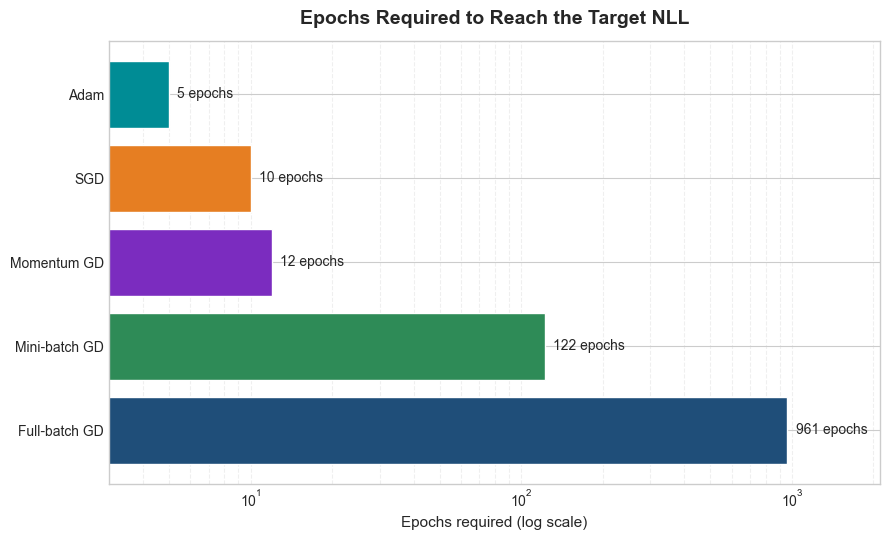

In [17]:
# Compare the epochs required to reach the target NLL.

optimizer_colors = {
    "Full-batch GD": "#1F4E79",
    "SGD": "#E67E22",
    "Mini-batch GD": "#2E8B57",
    "Momentum GD": "#7B2CBF",
    "Adam": "#008C95",
}

epoch_comparison = (
    handcrafted_comparison_table[
        [
            "Optimizer",
            "Epochs",
        ]
    ]
    .sort_values("Epochs")
    .reset_index(drop=True)
)

epoch_colors = [
    optimizer_colors[name]
    for name in epoch_comparison["Optimizer"]
]

figure, axis = plt.subplots(figsize=(9, 5.5))

bars = axis.barh(
    epoch_comparison["Optimizer"],
    epoch_comparison["Epochs"],
    color=epoch_colors,
    edgecolor="white",
)

axis.set_xscale("log")
axis.invert_yaxis()

axis.bar_label(
    bars,
    labels=[
        f"{int(value):,} epochs"
        for value in epoch_comparison["Epochs"]
    ],
    padding=6,
    fontsize=10,
)

axis.set_xlabel(
    "Epochs required (log scale)",
    fontsize=11,
)

axis.set_ylabel("")

axis.set_title(
    "Epochs Required to Reach the Target NLL",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.set_axisbelow(True)

axis.set_xlim(
    epoch_comparison["Epochs"].min() * 0.6,
    epoch_comparison["Epochs"].max() * 2.2,
)

plt.tight_layout()
plt.show()

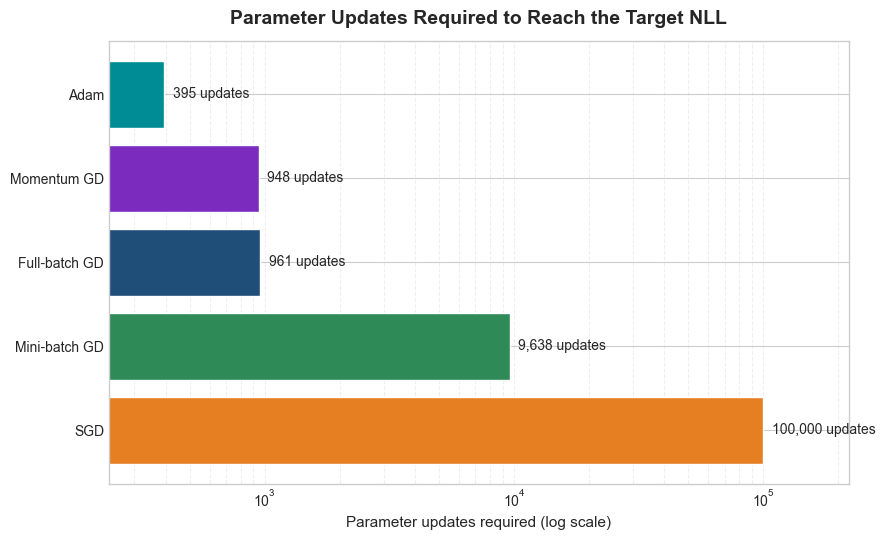

In [18]:
# Compare the parameter updates required to reach the target NLL.

update_comparison = (
    handcrafted_comparison_table[
        [
            "Optimizer",
            "Parameter updates",
        ]
    ]
    .sort_values("Parameter updates")
    .reset_index(drop=True)
)

update_colors = [
    optimizer_colors[name]
    for name in update_comparison["Optimizer"]
]

figure, axis = plt.subplots(figsize=(9, 5.5))

bars = axis.barh(
    update_comparison["Optimizer"],
    update_comparison["Parameter updates"],
    color=update_colors,
    edgecolor="white",
)

axis.set_xscale("log")
axis.invert_yaxis()

axis.bar_label(
    bars,
    labels=[
        f"{int(value):,} updates"
        for value in update_comparison[
            "Parameter updates"
        ]
    ],
    padding=6,
    fontsize=10,
)

axis.set_xlabel(
    "Parameter updates required (log scale)",
    fontsize=11,
)

axis.set_ylabel("")

axis.set_title(
    "Parameter Updates Required to Reach the Target NLL",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.set_axisbelow(True)

axis.set_xlim(
    update_comparison[
        "Parameter updates"
    ].min() * 0.6,
    update_comparison[
        "Parameter updates"
    ].max() * 2.2,
)

plt.tight_layout()
plt.show()

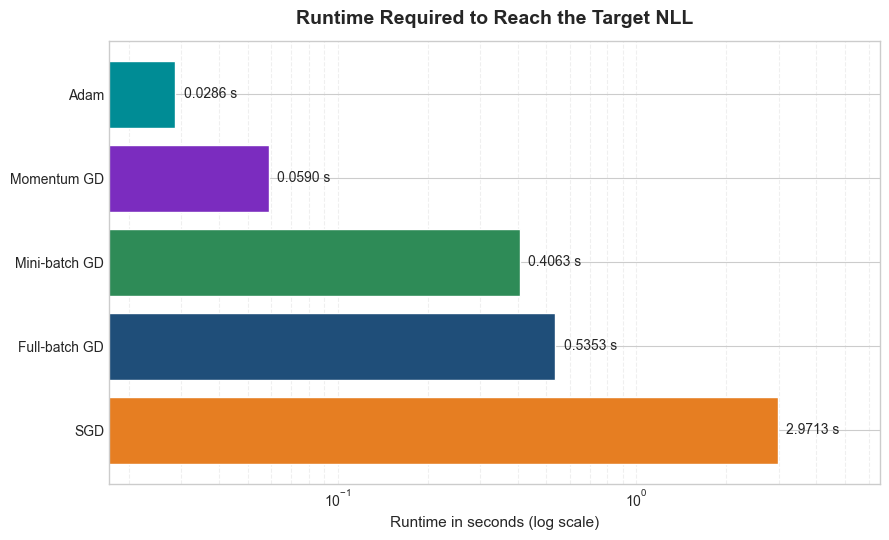

In [19]:
# Compare the measured runtime of each optimizer.

runtime_comparison = (
    handcrafted_comparison_table[
        [
            "Optimizer",
            "Runtime (seconds)",
        ]
    ]
    .sort_values("Runtime (seconds)")
    .reset_index(drop=True)
)

runtime_colors = [
    optimizer_colors[name]
    for name in runtime_comparison["Optimizer"]
]

figure, axis = plt.subplots(figsize=(9, 5.5))

bars = axis.barh(
    runtime_comparison["Optimizer"],
    runtime_comparison["Runtime (seconds)"],
    color=runtime_colors,
    edgecolor="white",
)

axis.set_xscale("log")
axis.invert_yaxis()

axis.bar_label(
    bars,
    labels=[
        f"{value:.4f} s"
        for value in runtime_comparison[
            "Runtime (seconds)"
        ]
    ],
    padding=6,
    fontsize=10,
)

axis.set_xlabel(
    "Runtime in seconds (log scale)",
    fontsize=11,
)

axis.set_ylabel("")

axis.set_title(
    "Runtime Required to Reach the Target NLL",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.set_axisbelow(True)

axis.set_xlim(
    runtime_comparison[
        "Runtime (seconds)"
    ].min() * 0.6,
    runtime_comparison[
        "Runtime (seconds)"
    ].max() * 2.2,
)

plt.tight_layout()
plt.show()

## PyTorch Optimizers
The same optimization experiments are now repeated using PyTorch.

In [20]:
# Define the shared PyTorch experiment settings.

PYTORCH_DEVICE = torch.device("cpu")
PYTORCH_DTYPE = torch.float64

torch.manual_seed(SEED)

pytorch_settings = pd.DataFrame({
    "Setting": [
        "PyTorch version",
        "Device",
        "Data type",
        "Random seed",
        "Number of items",
        "Number of comparisons",
        "Mini-batch size",
        "Reference NLL",
        "Target NLL",
    ],
    "Value": [
        torch.__version__,
        str(PYTORCH_DEVICE),
        str(PYTORCH_DTYPE),
        str(SEED),
        str(NUMBER_OF_ITEMS),
        f"{NUMBER_OF_COMPARISONS:,}",
        str(MINIBATCH_SIZE),
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
    ],
})

pytorch_settings

,Setting,Value
0,PyTorch version,2.13.0
1,Device,cpu
2,Data type,torch.float64
3,Random seed,20260831
4,Number of items,10
5,Number of comparisons,"10,000"
6,Mini-batch size,128
7,Reference NLL,0.5982
8,Target NLL,0.5983


In [21]:
# Temporary inspection of the reusable PyTorch functions written in /src folder.

import inspect
import bradley_terry.pytorch_optimization as bt_torch

pytorch_functions = pd.DataFrame(
    [
        {
            "Function": name,
            "Signature": str(inspect.signature(function)),
        }
        for name, function in vars(bt_torch).items()
        if callable(function)
        and function.__module__ == bt_torch.__name__
        and not name.startswith("_")
    ]
).sort_values("Function", ignore_index=True)

pytorch_functions

# print(
#     inspect.signature(
#         bt_torch.optimize_with_pytorch_full_batch_gradient_descent
#     )
# )

,Function,Signature
0,optimize_with_pytorch_adam,"(number_of_items: int, comparisons: collection..."
1,optimize_with_pytorch_full_batch_gradient_descent,"(number_of_items: int, comparisons: collection..."
2,optimize_with_pytorch_minibatch_gradient_descent,"(number_of_items: int, comparisons: collection..."
3,optimize_with_pytorch_momentum_gradient_descent,"(number_of_items: int, comparisons: collection..."
4,optimize_with_pytorch_stochastic_gradient_descent,"(number_of_items: int, comparisons: collection..."


### Experiment 6: PyTorch Full-Batch Gradient Descent

In [22]:
# Run PyTorch full-batch gradient descent until it reaches the common NLL target.

PYTORCH_FULL_BATCH_LEARNING_RATE = 0.1

pytorch_full_batch_result = (
    bt_torch.optimize_with_pytorch_full_batch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_FULL_BATCH_LEARNING_RATE,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_full_batch_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_full_batch_result.parameters,
)

pytorch_full_batch_target_reached = (
    pytorch_full_batch_result.nll_history[-1] <= target_nll
)

pytorch_full_batch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_FULL_BATCH_LEARNING_RATE:.4f}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_full_batch_result.nll_history[0]:.4f}",
        f"{pytorch_full_batch_result.nll_history[-1]:.4f}",
        f"{pytorch_full_batch_recovery_error:.4f}",
        f"{pytorch_full_batch_result.epochs_completed:,}",
        f"{int(pytorch_full_batch_result.update_count_history[-1]):,}",
        str(pytorch_full_batch_target_reached),
        pytorch_full_batch_result.stopping_reason,
        f"{pytorch_full_batch_result.runtime_seconds:.4f}",
        f"{pytorch_full_batch_result.parameters.sum():.4e}",
    ],
})

pytorch_full_batch_summary

,Quantity,Value
0,Learning rate,0.1000
1,Reference full-batch NLL,0.5982
2,Target NLL,0.5983
3,Initial NLL,0.6931
4,Final NLL,0.5983
5,Parameter-recovery RMSE,0.0437
6,Epochs completed,961
7,Parameter updates,961
8,Target reached,True
9,Stopping reason,target NLL reached


Here, we can see that the difference between the result of using handcraft technique and pytorch has just one: the runtime, as runtime Handcrafted is 0.59 but pytorch is 0.75
The reason of the same is the autograd overhead for a small BTL model problems makes it slightly slower as the parameter count taken till now was also 10 parameters, and maybe for all the next experiments having just '10 params', the runtime might be greater.

### Experiment 7: PyTorch Stochastic Gradient Descent


In [23]:
# Run PyTorch SGD until it reaches the common NLL target.

PYTORCH_SGD_LEARNING_RATE = 0.001

pytorch_sgd_result = (
    bt_torch.optimize_with_pytorch_stochastic_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_SGD_LEARNING_RATE,
        random_seed=SEED,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_sgd_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_sgd_result.parameters,
)

pytorch_sgd_target_reached = (
    pytorch_sgd_result.nll_history[-1] <= target_nll
)

pytorch_sgd_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Reference full-batch NLL",
        "Allowed NLL margin",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_SGD_LEARNING_RATE:.4f}",
        f"{reference_nll:.4f}",
        f"{NLL_TARGET_MARGIN:.4e}",
        f"{target_nll:.4f}",
        f"{pytorch_sgd_result.nll_history[0]:.4f}",
        f"{pytorch_sgd_result.nll_history[-1]:.4f}",
        f"{pytorch_sgd_recovery_error:.4f}",
        f"{pytorch_sgd_result.epochs_completed:,}",
        f"{int(pytorch_sgd_result.update_count_history[-1]):,}",
        str(pytorch_sgd_target_reached),
        pytorch_sgd_result.stopping_reason,
        f"{pytorch_sgd_result.runtime_seconds:.4f}",
        f"{pytorch_sgd_result.parameters.sum():.4e}",
    ],
})

pytorch_sgd_summary

,Quantity,Value
0,Learning rate,0.0010
1,Reference full-batch NLL,0.5982
2,Allowed NLL margin,1.0000e-04
3,Target NLL,0.5983
4,Initial NLL,0.6931
5,Final NLL,0.5983
6,Parameter-recovery RMSE,0.0411
7,Epochs completed,10
8,Parameter updates,"100,000"
9,Target reached,True


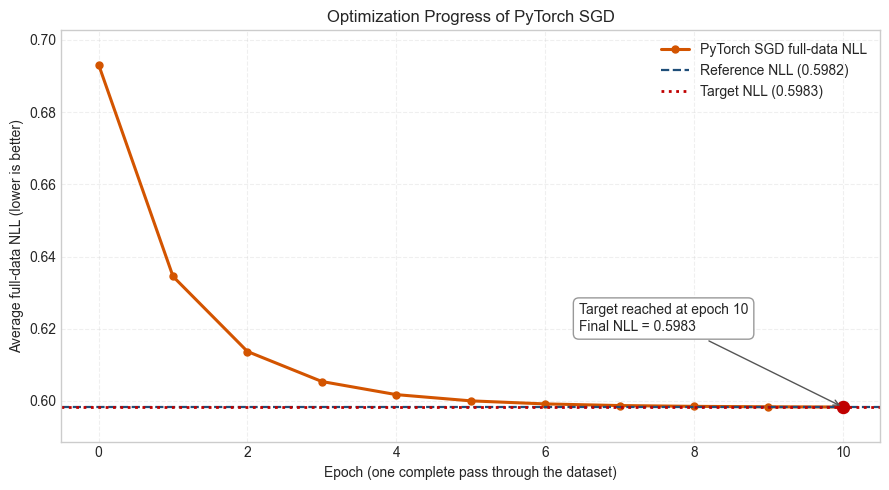

In [24]:
# Plot the full-data NLL measured after each PyTorch SGD epoch.

pytorch_sgd_epochs = np.arange(
    len(pytorch_sgd_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_sgd_epochs,
    pytorch_sgd_result.nll_history,
    color="#D35400",
    marker="o",
    markersize=5,
    linewidth=2.2,
    label="PyTorch SGD full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_sgd_epochs[-1]
final_nll = pytorch_sgd_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch SGD")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 8: PyTorch Mini-Batch Gradient Descent


In [25]:
# Run PyTorch mini-batch GD until it reaches the common NLL target.

PYTORCH_MINIBATCH_LEARNING_RATE = 0.05

pytorch_minibatch_result = (
    bt_torch.optimize_with_pytorch_minibatch_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_MINIBATCH_LEARNING_RATE,
        batch_size=MINIBATCH_SIZE,
        random_seed=SEED,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_minibatch_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_minibatch_result.parameters,
)

pytorch_minibatch_target_reached = (
    pytorch_minibatch_result.nll_history[-1] <= target_nll
)

pytorch_minibatch_batches_per_epoch = int(
    np.ceil(NUMBER_OF_COMPARISONS / MINIBATCH_SIZE)
)

pytorch_minibatch_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_MINIBATCH_LEARNING_RATE:.4f}",
        f"{MINIBATCH_SIZE:,}",
        f"{pytorch_minibatch_batches_per_epoch:,}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_minibatch_result.nll_history[0]:.4f}",
        f"{pytorch_minibatch_result.nll_history[-1]:.4f}",
        f"{pytorch_minibatch_recovery_error:.4f}",
        f"{pytorch_minibatch_result.epochs_completed:,}",
        f"{int(pytorch_minibatch_result.update_count_history[-1]):,}",
        str(pytorch_minibatch_target_reached),
        pytorch_minibatch_result.stopping_reason,
        f"{pytorch_minibatch_result.runtime_seconds:.4f}",
        f"{pytorch_minibatch_result.parameters.sum():.4e}",
    ],
})

pytorch_minibatch_summary

,Quantity,Value
0,Learning rate,0.0500
1,Mini-batch size,128
2,Batches per epoch,79
3,Reference full-batch NLL,0.5982
4,Target NLL,0.5983
5,Initial NLL,0.6931
6,Final NLL,0.5983
7,Parameter-recovery RMSE,0.0422
8,Epochs completed,24
9,Parameter updates,"1,896"


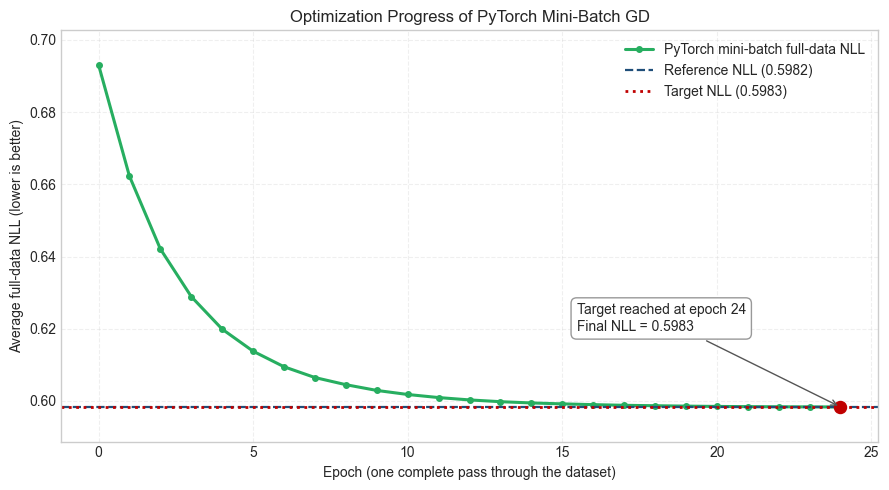

In [26]:
# Plot the full-data NLL measured after each PyTorch mini-batch epoch.

pytorch_minibatch_epochs = np.arange(
    len(pytorch_minibatch_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_minibatch_epochs,
    pytorch_minibatch_result.nll_history,
    color="#27AE60",
    marker="o",
    markersize=4,
    linewidth=2.2,
    label="PyTorch mini-batch full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_minibatch_epochs[-1]
final_nll = pytorch_minibatch_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch Mini-Batch GD")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 9: PyTorch Momentum Gradient Descent


In [27]:
# Run PyTorch momentum GD until it reaches the common NLL target.

PYTORCH_MOMENTUM_LEARNING_RATE = 0.01
PYTORCH_MOMENTUM_COEFFICIENT = 0.9

pytorch_momentum_result = (
    bt_torch.optimize_with_pytorch_momentum_gradient_descent(
        number_of_items=NUMBER_OF_ITEMS,
        comparisons=comparisons,
        learning_rate=PYTORCH_MOMENTUM_LEARNING_RATE,
        batch_size=MINIBATCH_SIZE,
        momentum=PYTORCH_MOMENTUM_COEFFICIENT,
        random_seed=SEED,
        gradient_tolerance=GRADIENT_TOLERANCE,
        target_nll=target_nll,
        initial_parameters=np.zeros(NUMBER_OF_ITEMS),
    )
)

pytorch_momentum_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_momentum_result.parameters,
)

pytorch_momentum_target_reached = (
    pytorch_momentum_result.nll_history[-1] <= target_nll
)

pytorch_momentum_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Momentum coefficient",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_MOMENTUM_LEARNING_RATE:.4f}",
        f"{PYTORCH_MOMENTUM_COEFFICIENT:.4f}",
        f"{MINIBATCH_SIZE:,}",
        f"{pytorch_minibatch_batches_per_epoch:,}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_momentum_result.nll_history[0]:.4f}",
        f"{pytorch_momentum_result.nll_history[-1]:.4f}",
        f"{pytorch_momentum_recovery_error:.4f}",
        f"{pytorch_momentum_result.epochs_completed:,}",
        f"{int(pytorch_momentum_result.update_count_history[-1]):,}",
        str(pytorch_momentum_target_reached),
        pytorch_momentum_result.stopping_reason,
        f"{pytorch_momentum_result.runtime_seconds:.4f}",
        f"{pytorch_momentum_result.parameters.sum():.4e}",
    ],
})

pytorch_momentum_summary

,Quantity,Value
0,Learning rate,0.0100
1,Momentum coefficient,0.9000
2,Mini-batch size,128
3,Batches per epoch,79
4,Reference full-batch NLL,0.5982
5,Target NLL,0.5983
6,Initial NLL,0.6931
7,Final NLL,0.5983
8,Parameter-recovery RMSE,0.0432
9,Epochs completed,12


Here, learning rate 0.01, momentum 0.9, and batch size 128, was deliberstely used to match the handcrafted momentum experiment for a fair comparison.

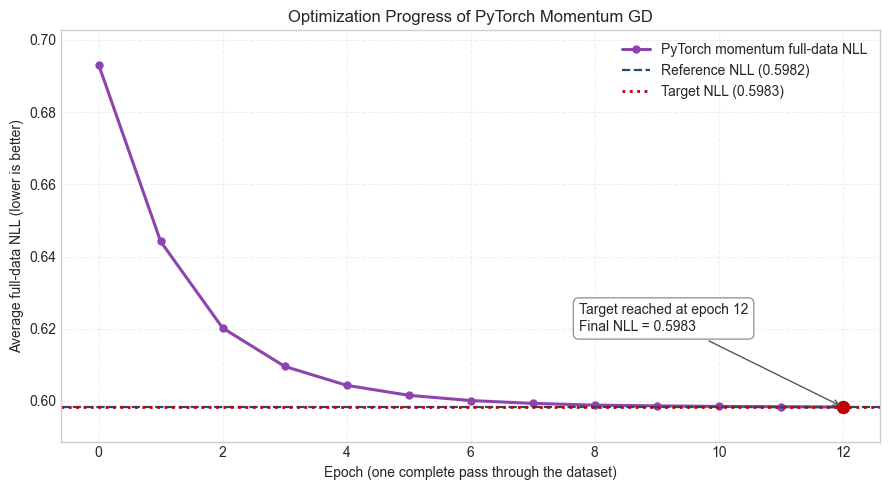

In [28]:
# Plot the full-data NLL measured after each PyTorch momentum epoch.

pytorch_momentum_epochs = np.arange(
    len(pytorch_momentum_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_momentum_epochs,
    pytorch_momentum_result.nll_history,
    color="#8E44AD",
    marker="o",
    markersize=5,
    linewidth=2.2,
    label="PyTorch momentum full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_momentum_epochs[-1]
final_nll = pytorch_momentum_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch Momentum GD")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

### Experiment 10: PyTorch Adam


In [29]:
# Run PyTorch Adam until it reaches the common NLL target.

PYTORCH_ADAM_LEARNING_RATE = 0.01
PYTORCH_ADAM_BETA_1 = 0.9
PYTORCH_ADAM_BETA_2 = 0.999
PYTORCH_ADAM_EPSILON = 1e-8

pytorch_adam_result = bt_torch.optimize_with_pytorch_adam(
    number_of_items=NUMBER_OF_ITEMS,
    comparisons=comparisons,
    learning_rate=PYTORCH_ADAM_LEARNING_RATE,
    batch_size=MINIBATCH_SIZE,
    beta_1=PYTORCH_ADAM_BETA_1,
    beta_2=PYTORCH_ADAM_BETA_2,
    epsilon=PYTORCH_ADAM_EPSILON,
    random_seed=SEED,
    gradient_tolerance=GRADIENT_TOLERANCE,
    target_nll=target_nll,
    initial_parameters=np.zeros(NUMBER_OF_ITEMS),
)

pytorch_adam_recovery_error = parameter_recovery_error(
    true_parameters,
    pytorch_adam_result.parameters,
)

pytorch_adam_target_reached = (
    pytorch_adam_result.nll_history[-1] <= target_nll
)

pytorch_adam_summary = pd.DataFrame({
    "Quantity": [
        "Learning rate",
        "Beta 1",
        "Beta 2",
        "Epsilon",
        "Mini-batch size",
        "Batches per epoch",
        "Reference full-batch NLL",
        "Target NLL",
        "Initial NLL",
        "Final NLL",
        "Parameter-recovery RMSE",
        "Epochs completed",
        "Parameter updates",
        "Target reached",
        "Stopping reason",
        "Runtime in seconds",
        "Sum of estimated parameters",
    ],
    "Value": [
        f"{PYTORCH_ADAM_LEARNING_RATE:.4f}",
        f"{PYTORCH_ADAM_BETA_1:.4f}",
        f"{PYTORCH_ADAM_BETA_2:.4f}",
        f"{PYTORCH_ADAM_EPSILON:.1e}",
        f"{MINIBATCH_SIZE:,}",
        f"{pytorch_minibatch_batches_per_epoch:,}",
        f"{reference_nll:.4f}",
        f"{target_nll:.4f}",
        f"{pytorch_adam_result.nll_history[0]:.4f}",
        f"{pytorch_adam_result.nll_history[-1]:.4f}",
        f"{pytorch_adam_recovery_error:.4f}",
        f"{pytorch_adam_result.epochs_completed:,}",
        f"{int(pytorch_adam_result.update_count_history[-1]):,}",
        str(pytorch_adam_target_reached),
        pytorch_adam_result.stopping_reason,
        f"{pytorch_adam_result.runtime_seconds:.4f}",
        f"{pytorch_adam_result.parameters.sum():.4e}",
    ],
})

pytorch_adam_summary

,Quantity,Value
0,Learning rate,0.0100
1,Beta 1,0.9000
2,Beta 2,0.9990
3,Epsilon,1.0e-08
4,Mini-batch size,128
5,Batches per epoch,79
6,Reference full-batch NLL,0.5982
7,Target NLL,0.5983
8,Initial NLL,0.6931
9,Final NLL,0.5983


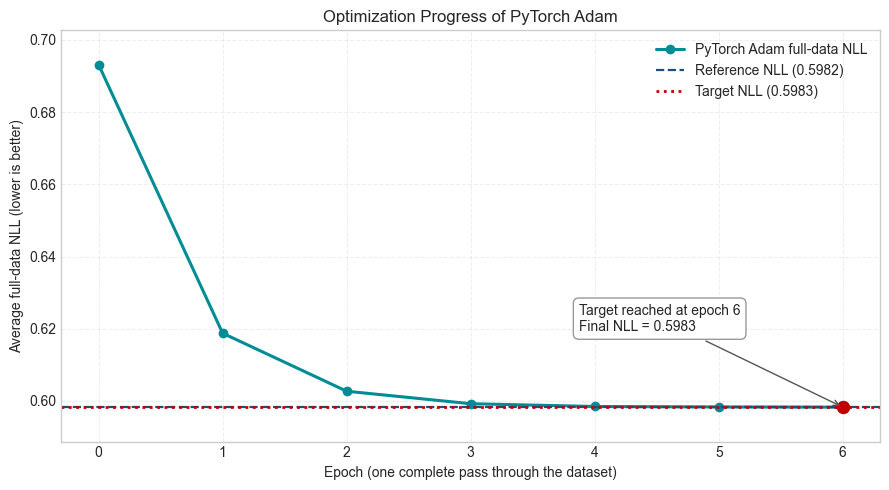

In [30]:
# Plot the full-data NLL measured after each PyTorch Adam epoch.

pytorch_adam_epochs = np.arange(
    len(pytorch_adam_result.nll_history)
)

figure, axis = plt.subplots(figsize=(9, 5))

axis.plot(
    pytorch_adam_epochs,
    pytorch_adam_result.nll_history,
    color="#008C95",
    marker="o",
    markersize=6,
    linewidth=2.2,
    label="PyTorch Adam full-data NLL",
)

axis.axhline(
    reference_nll,
    color="#1F4E79",
    linestyle="--",
    linewidth=1.6,
    label=f"Reference NLL ({reference_nll:.4f})",
)

axis.axhline(
    target_nll,
    color="#C00000",
    linestyle=":",
    linewidth=2,
    label=f"Target NLL ({target_nll:.4f})",
)

final_epoch = pytorch_adam_epochs[-1]
final_nll = pytorch_adam_result.nll_history[-1]

axis.scatter(
    final_epoch,
    final_nll,
    color="#C00000",
    s=75,
    zorder=3,
)

axis.annotate(
    f"Target reached at epoch {final_epoch:,}\n"
    f"Final NLL = {final_nll:.4f}",
    xy=(final_epoch, final_nll),
    xytext=(-190, 55),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#555555"},
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#999999",
    },
)

axis.set_xlabel("Epoch (one complete pass through the dataset)")
axis.set_ylabel("Average full-data NLL (lower is better)")
axis.set_title("Optimization Progress of PyTorch Adam")
axis.legend(loc="upper right")
axis.grid(True, linestyle="--", alpha=0.3)
axis.margins(x=0.05, y=0.1)

plt.tight_layout()
plt.show()

## Comparison of Handcrafted and PyTorch Optimizers


In [31]:
# Collect all handcrafted and PyTorch results in one comparison table.

optimizer_results = [
    (
        "Handcrafted",
        "Full-batch GD",
        NUMBER_OF_COMPARISONS,
        full_batch_target_result,
    ),
    (
        "PyTorch",
        "Full-batch GD",
        NUMBER_OF_COMPARISONS,
        pytorch_full_batch_result,
    ),
    (
        "Handcrafted",
        "SGD",
        1,
        sgd_result,
    ),
    (
        "PyTorch",
        "SGD",
        1,
        pytorch_sgd_result,
    ),
    (
        "Handcrafted",
        "Mini-batch GD",
        MINIBATCH_SIZE,
        minibatch_result,
    ),
    (
        "PyTorch",
        "Mini-batch GD",
        MINIBATCH_SIZE,
        pytorch_minibatch_result,
    ),
    (
        "Handcrafted",
        "Momentum GD",
        MINIBATCH_SIZE,
        momentum_result,
    ),
    (
        "PyTorch",
        "Momentum GD",
        MINIBATCH_SIZE,
        pytorch_momentum_result,
    ),
    (
        "Handcrafted",
        "Adam",
        MINIBATCH_SIZE,
        adam_result,
    ),
    (
        "PyTorch",
        "Adam",
        MINIBATCH_SIZE,
        pytorch_adam_result,
    ),
]

comparison_rows = []

for implementation, optimizer, batch_size, result in optimizer_results:
    comparison_rows.append({
        "Implementation": implementation,
        "Optimizer": optimizer,
        "Batch size": batch_size,
        "Final NLL": result.nll_history[-1],
        "Recovery RMSE": parameter_recovery_error(
            true_parameters,
            result.parameters,
        ),
        "Epochs": result.epochs_completed,
        "Parameter updates": int(result.update_count_history[-1]),
        "Runtime (seconds)": result.runtime_seconds,
        "Target reached": result.nll_history[-1] <= target_nll,
    })

combined_comparison_table = pd.DataFrame(comparison_rows)

combined_comparison_table.style.format({
    "Batch size": "{:,}",
    "Final NLL": "{:.4f}",
    "Recovery RMSE": "{:.4f}",
    "Epochs": "{:,}",
    "Parameter updates": "{:,}",
    "Runtime (seconds)": "{:.4f}",
})

,Implementation,Optimizer,Batch size,Final NLL,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Target reached
0,Handcrafted,Full-batch GD,"10,000",0.5983,0.0437,961,961,0.5353,True
1,PyTorch,Full-batch GD,"10,000",0.5983,0.0437,961,961,0.7730,True
2,Handcrafted,SGD,1,0.5983,0.0440,10,"100,000",2.9713,True
3,PyTorch,SGD,1,0.5983,0.0411,10,"100,000",7.4522,True
4,Handcrafted,Mini-batch GD,128,0.5983,0.0439,122,"9,638",0.4063,True
5,PyTorch,Mini-batch GD,128,0.5983,0.0422,24,"1,896",0.1713,True
6,Handcrafted,Momentum GD,128,0.5983,0.0463,12,948,0.0590,True
7,PyTorch,Momentum GD,128,0.5983,0.0432,12,948,0.1030,True
8,Handcrafted,Adam,128,0.5983,0.0359,5,395,0.0286,True
9,PyTorch,Adam,128,0.5983,0.0397,6,474,0.0633,True


### Epoch Comparison


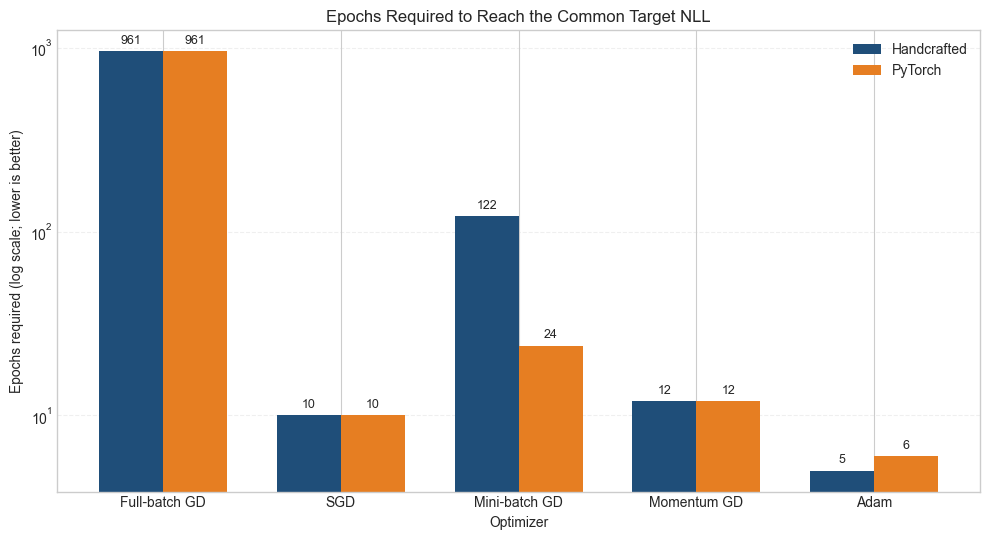

In [32]:
# Compare the epochs required by handcrafted and PyTorch optimizers.

optimizer_order = [
    "Full-batch GD",
    "SGD",
    "Mini-batch GD",
    "Momentum GD",
    "Adam",
]

epoch_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Epochs",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    epoch_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    epoch_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{int(value):,}"
        for value in epoch_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{int(value):,}"
        for value in epoch_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_yscale("log")
axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Epochs required (log scale; lower is better)")
axis.set_title("Epochs Required to Reach the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Parameter-Update Comparison


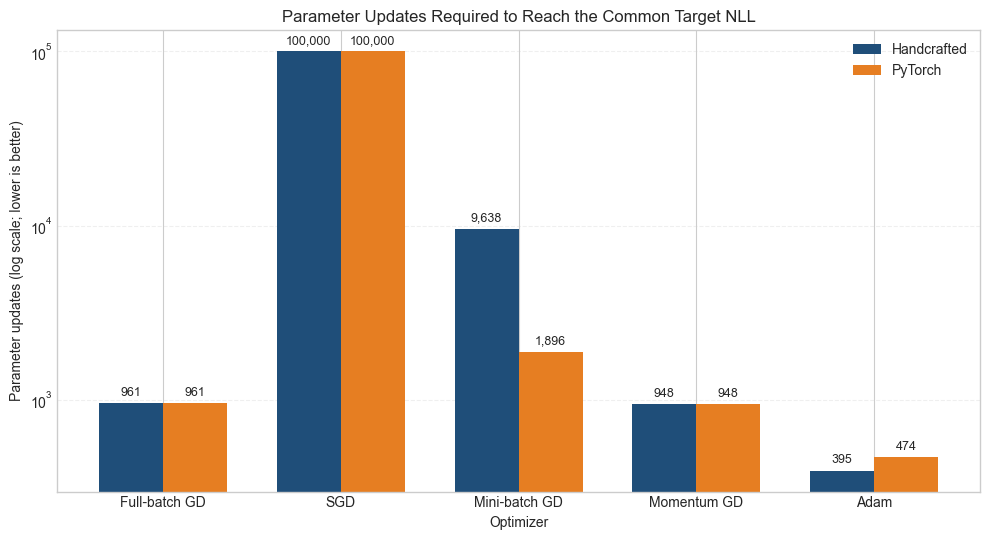

In [33]:
# Compare the number of parameter updates required to reach the target.

update_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Parameter updates",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    update_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    update_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{int(value):,}"
        for value in update_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{int(value):,}"
        for value in update_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_yscale("log")
axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Parameter updates (log scale; lower is better)")
axis.set_title("Parameter Updates Required to Reach the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Runtime Comparison


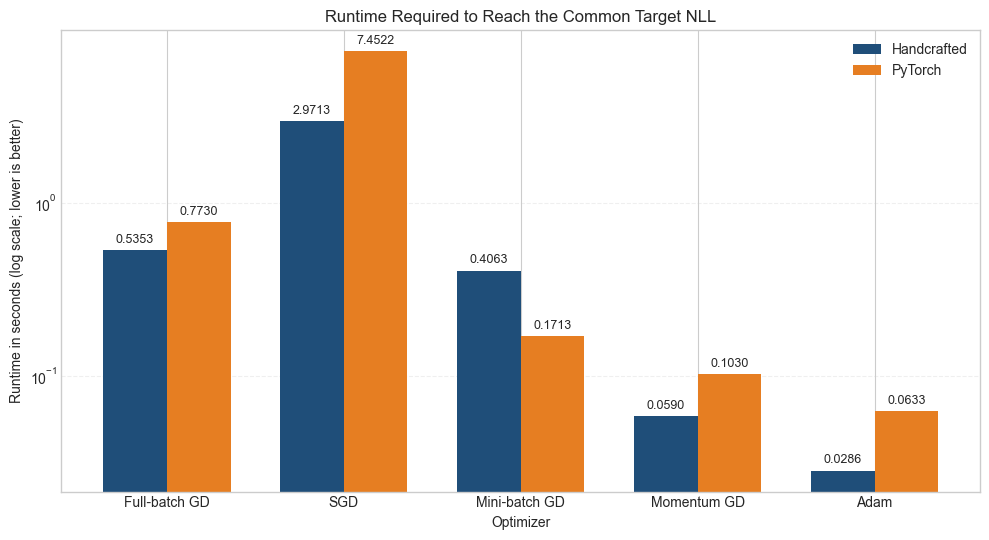

In [34]:

# Compare the measured runtime of handcrafted and PyTorch optimizers.

runtime_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Runtime (seconds)",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    runtime_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    runtime_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{value:.4f}"
        for value in runtime_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{value:.4f}"
        for value in runtime_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_yscale("log")
axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Runtime in seconds (log scale; lower is better)")
axis.set_title("Runtime Required to Reach the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Parameter-Recovery Comparison


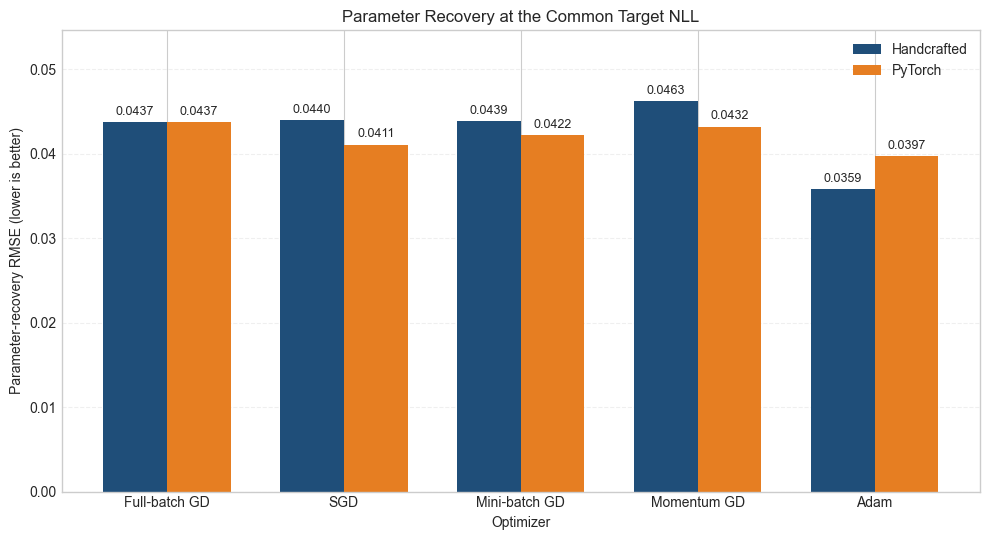

In [35]:
# Compare parameter-recovery RMSE across both implementations.

rmse_plot_data = (
    combined_comparison_table
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Recovery RMSE",
    )
    .reindex(optimizer_order)
)

x_positions = np.arange(len(optimizer_order))
bar_width = 0.36

figure, axis = plt.subplots(figsize=(10, 5.5))

handcrafted_bars = axis.bar(
    x_positions - bar_width / 2,
    rmse_plot_data["Handcrafted"],
    width=bar_width,
    color="#1F4E79",
    label="Handcrafted",
)

pytorch_bars = axis.bar(
    x_positions + bar_width / 2,
    rmse_plot_data["PyTorch"],
    width=bar_width,
    color="#E67E22",
    label="PyTorch",
)

axis.bar_label(
    handcrafted_bars,
    labels=[
        f"{value:.4f}"
        for value in rmse_plot_data["Handcrafted"]
    ],
    padding=3,
    fontsize=9,
)

axis.bar_label(
    pytorch_bars,
    labels=[
        f"{value:.4f}"
        for value in rmse_plot_data["PyTorch"]
    ],
    padding=3,
    fontsize=9,
)

axis.set_xticks(x_positions)
axis.set_xticklabels(optimizer_order)
axis.set_xlabel("Optimizer")
axis.set_ylabel("Parameter-recovery RMSE (lower is better)")
axis.set_title("Parameter Recovery at the Common Target NLL")
axis.legend()
axis.grid(axis="y", linestyle="--", alpha=0.3)
axis.set_ylim(
    0,
    1.18 * max(
        rmse_plot_data["Handcrafted"].max(),
        rmse_plot_data["PyTorch"].max(),
    ),
)

plt.tight_layout()
plt.show()

### Now, to try for larger n and larger comparisons

In [41]:
# Check whether the Apple GPU is available through PyTorch MPS.

mps_status = pd.DataFrame({
    "Check": [
        "MPS support built into PyTorch",
        "MPS device currently available",
        "Selected device",
        "Selected dtype",
    ],
    "Value": [
        str(torch.backends.mps.is_built()),
        str(torch.backends.mps.is_available()),
        "mps" if torch.backends.mps.is_available() else "unavailable",
        "torch.float32",
    ],
})

mps_status

,Check,Value
0,MPS support built into PyTorch,True
1,MPS device currently available,True
2,Selected device,mps
3,Selected dtype,torch.float32


In [44]:
# Define the settings for the CPU-versus-MPS scaling experiments.

SCALING_ITEM_COUNTS = [10, 50, 100]
FIXED_SCALING_COMPARISONS = 100_000

SCALING_COMPARISON_COUNTS = [10_000, 50_000, 100_000]
FIXED_SCALING_ITEMS = 50

NUMBER_OF_SCALING_RUNS = 10
SCALING_BATCH_SIZE = 1_024
SCALING_OPTIMIZER = "Adam"

SCALING_DEVICE = torch.device("mps")
SCALING_DTYPE = torch.float32

SCALING_SEEDS = [
    SEED + run_index
    for run_index in range(NUMBER_OF_SCALING_RUNS)
]

scaling_settings = pd.DataFrame({
    "Setting": [
        "Optimizer",
        "Item counts",
        "Fixed comparisons for item experiment",
        "Comparison counts",
        "Fixed items for comparison experiment",
        "Independent runs per setting",
        "Mini-batch size",
        "Handcrafted device",
        "PyTorch device",
        "PyTorch dtype",
    ],
    "Value": [
        SCALING_OPTIMIZER,
        str(SCALING_ITEM_COUNTS),
        f"{FIXED_SCALING_COMPARISONS:,}",
        str(SCALING_COMPARISON_COUNTS),
        f"{FIXED_SCALING_ITEMS:,}",
        f"{NUMBER_OF_SCALING_RUNS}",
        f"{SCALING_BATCH_SIZE:,}",
        "CPU",
        str(SCALING_DEVICE),
        str(SCALING_DTYPE),
    ],
})

scaling_settings

,Setting,Value
0,Optimizer,Adam
1,Item counts,"[10, 50, 100]"
2,Fixed comparisons for item experiment,"100,000"
3,Comparison counts,"[10000, 50000, 100000]"
4,Fixed items for comparison experiment,50
5,Independent runs per setting,10
6,Mini-batch size,"1,024"
7,Handcrafted device,CPU
8,PyTorch device,mps
9,PyTorch dtype,torch.float32


In [52]:
# Run handcrafted Adam on CPU and PyTorch Adam on MPS using the same data.

SCALING_LEARNING_RATE = 0.01
SCALING_NLL_MARGIN = 1e-4
SCALING_GRADIENT_TOLERANCE = 1e-6


def run_cpu_mps_adam_trial(
    number_of_items,
    number_of_comparisons,
    random_seed,
    batch_size=SCALING_BATCH_SIZE,
):
    trial_rng = np.random.default_rng(random_seed)

    # Generate the true centered Bradley–Terry parameters.
    trial_true_parameters = center_parameters(
        trial_rng.normal(
            loc=0.0,
            scale=1.0,
            size=number_of_items,
        )
    )

    # Generate one dataset shared by both implementations.
    trial_comparisons = generate_uniform_comparison_data(
        true_parameters=trial_true_parameters,
        number_of_comparisons=number_of_comparisons,
        rng=trial_rng,
    )

    # Both implementations begin from zero parameters.
    trial_initial_parameters = np.zeros(
        number_of_items,
        dtype=float,
    )

    # Define a reachable stopping target.
    true_parameter_nll = average_negative_log_likelihood(
        trial_true_parameters,
        trial_comparisons,
    )

    trial_target_nll = (
        true_parameter_nll + SCALING_NLL_MARGIN
    )

    # Run handcrafted Adam on the CPU.
    handcrafted_result = optimize_with_adam(
        number_of_items=number_of_items,
        comparisons=trial_comparisons,
        learning_rate=SCALING_LEARNING_RATE,
        batch_size=batch_size,
        random_seed=random_seed,
        gradient_tolerance=SCALING_GRADIENT_TOLERANCE,
        target_nll=trial_target_nll,
        shuffle=True,
    )

    # Run PyTorch Adam on Apple MPS.
    pytorch_mps_result = (
        bt_torch.optimize_with_pytorch_adam(
            number_of_items=number_of_items,
            comparisons=trial_comparisons,
            learning_rate=SCALING_LEARNING_RATE,
            batch_size=batch_size,
            random_seed=random_seed,
            gradient_tolerance=(
                SCALING_GRADIENT_TOLERANCE
            ),
            target_nll=trial_target_nll,
            initial_parameters=trial_initial_parameters,
            device=SCALING_DEVICE,
            dtype=SCALING_DTYPE,
        )
    )

    # Confirm that both implementations started equally.
    if not np.isclose(
        handcrafted_result.nll_history[0],
        pytorch_mps_result.nll_history[0],
        atol=1e-5,
    ):
        raise RuntimeError(
            "CPU and MPS implementations used "
            "different initializations."
        )

    result_rows = []

    for implementation, device, result in [
        (
            "Handcrafted",
            "CPU",
            handcrafted_result,
        ),
        (
            "PyTorch",
            "MPS",
            pytorch_mps_result,
        ),
    ]:
        target_reached = (
            result.nll_history[-1]
            <= trial_target_nll
        )

        if not target_reached:
            raise RuntimeError(
                f"{implementation} did not reach the "
                f"target NLL for seed {random_seed}."
            )

        result_rows.append({
            "Implementation": implementation,
            "Device": device,
            "Number of items": number_of_items,
            "Number of comparisons": (
                number_of_comparisons
            ),
            "Random seed": random_seed,
            "Initial NLL": result.nll_history[0],
            "Target NLL": trial_target_nll,
            "Final NLL": result.nll_history[-1],
            "Recovery RMSE": parameter_recovery_error(
                trial_true_parameters,
                result.parameters,
            ),
            "Epochs": result.epochs_completed,
            "Parameter updates": int(
                result.update_count_history[-1]
            ),
            "Runtime (seconds)": (
                result.runtime_seconds
            ),
            "Target reached": target_reached,
        })

    return result_rows

In [47]:
# Test the complete CPU-versus-MPS pipeline on one small setting.
# smoke testing
scaling_smoke_test = pd.DataFrame(
    run_cpu_mps_adam_trial(
        number_of_items=10,
        number_of_comparisons=10_000,
        random_seed=SCALING_SEEDS[0],
    )
)

scaling_smoke_test.style.format({
    "Number of comparisons": "{:,}",
    "Initial NLL": "{:.4f}",
    "Target NLL": "{:.4f}",
    "Final NLL": "{:.4f}",
    "Recovery RMSE": "{:.4f}",
    "Epochs": "{:,}",
    "Parameter updates": "{:,}",
    "Runtime (seconds)": "{:.4f}",
})

,Implementation,Device,Number of items,Number of comparisons,Random seed,Initial NLL,Target NLL,Final NLL,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Target reached
0,Handcrafted,CPU,10,"10,000",20260831,0.6931,0.5613,0.5612,0.0616,34,340,0.0506,True
1,PyTorch,MPS,10,"10,000",20260831,0.6931,0.5613,0.5612,0.0585,34,340,0.4582,True


#### Scaling with the Number of Items
Here in this experiment the number of comparison is fixed to 1,00,000 while the number of items(n) is varying
And the handcraft adam runs on cpu, while pytorch adam runs on gpu(mps)

In [49]:
# Compare CPU and MPS performance while varying the number of items.

item_scaling_rows = []

total_trials = (
    len(SCALING_ITEM_COUNTS)
    * NUMBER_OF_SCALING_RUNS
)

completed_trials = 0

for number_of_items in SCALING_ITEM_COUNTS:
    for run_number, random_seed in enumerate(
        SCALING_SEEDS,
        start=1,
    ):
        completed_trials += 1

        print(
            f"Running trial {completed_trials}/{total_trials}: "
            f"items={number_of_items}, "
            f"comparisons={FIXED_SCALING_COMPARISONS:,}, "
            f"run={run_number}"
        )

        trial_rows = run_cpu_mps_adam_trial(
            number_of_items=number_of_items,
            number_of_comparisons=(
                FIXED_SCALING_COMPARISONS
            ),
            random_seed=random_seed,
        )

        for row in trial_rows:
            row["Experiment"] = "Varying items"
            row["Run"] = run_number

        item_scaling_rows.extend(trial_rows)

item_scaling_results = pd.DataFrame(
    item_scaling_rows
)

print("\nAll item-scaling trials completed.")

item_scaling_results.head(10).style.format({
    "Number of comparisons": "{:,}",
    "Initial NLL": "{:.4f}",
    "Target NLL": "{:.4f}",
    "Final NLL": "{:.4f}",
    "Recovery RMSE": "{:.4f}",
    "Epochs": "{:,}",
    "Parameter updates": "{:,}",
    "Runtime (seconds)": "{:.4f}",
})

Running trial 1/30: items=10, comparisons=100,000, run=1
Running trial 2/30: items=10, comparisons=100,000, run=2
Running trial 3/30: items=10, comparisons=100,000, run=3
Running trial 4/30: items=10, comparisons=100,000, run=4
Running trial 5/30: items=10, comparisons=100,000, run=5
Running trial 6/30: items=10, comparisons=100,000, run=6
Running trial 7/30: items=10, comparisons=100,000, run=7
Running trial 8/30: items=10, comparisons=100,000, run=8
Running trial 9/30: items=10, comparisons=100,000, run=9
Running trial 10/30: items=10, comparisons=100,000, run=10
Running trial 11/30: items=50, comparisons=100,000, run=1
Running trial 12/30: items=50, comparisons=100,000, run=2
Running trial 13/30: items=50, comparisons=100,000, run=3
Running trial 14/30: items=50, comparisons=100,000, run=4
Running trial 15/30: items=50, comparisons=100,000, run=5
Running trial 16/30: items=50, comparisons=100,000, run=6
Running trial 17/30: items=50, comparisons=100,000, run=7
Running trial 18/30: i

,Implementation,Device,Number of items,Number of comparisons,Random seed,Initial NLL,Target NLL,Final NLL,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Target reached,Experiment,Run
0,Handcrafted,CPU,10,"100,000",20260831,0.6931,0.5648,0.5648,0.0276,5,490,0.0698,True,Varying items,1
1,PyTorch,MPS,10,"100,000",20260831,0.6931,0.5648,0.5647,0.0246,5,490,0.4405,True,Varying items,1
2,Handcrafted,CPU,10,"100,000",20260832,0.6931,0.5135,0.5134,0.0325,4,392,0.0497,True,Varying items,2
3,PyTorch,MPS,10,"100,000",20260832,0.6931,0.5135,0.5134,0.0180,5,490,0.3553,True,Varying items,2
4,Handcrafted,CPU,10,"100,000",20260833,0.6931,0.5325,0.5324,0.0235,5,490,0.0612,True,Varying items,3
5,PyTorch,MPS,10,"100,000",20260833,0.6931,0.5325,0.5325,0.0253,5,490,0.3509,True,Varying items,3
6,Handcrafted,CPU,10,"100,000",20260834,0.6931,0.5688,0.5687,0.0137,4,392,0.0539,True,Varying items,4
7,PyTorch,MPS,10,"100,000",20260834,0.6931,0.5688,0.5687,0.0154,4,392,0.3923,True,Varying items,4
8,Handcrafted,CPU,10,"100,000",20260835,0.6931,0.4967,0.4966,0.0280,5,490,0.0633,True,Varying items,5
9,PyTorch,MPS,10,"100,000",20260835,0.6931,0.4967,0.4966,0.0265,5,490,0.3701,True,Varying items,5


In [50]:
# Summarize runtime and optimization results across the repeated runs.

item_scaling_summary = (
    item_scaling_results
    .groupby(
        [
            "Number of items",
            "Implementation",
            "Device",
        ],
        as_index=False,
    )
    .agg(
        Mean_runtime=("Runtime (seconds)", "mean"),
        Runtime_std=("Runtime (seconds)", "std"),
        Mean_epochs=("Epochs", "mean"),
        Mean_updates=("Parameter updates", "mean"),
        Mean_recovery_RMSE=("Recovery RMSE", "mean"),
    )
)

item_scaling_summary.style.format({
    "Mean_runtime": "{:.4f}",
    "Runtime_std": "{:.4f}",
    "Mean_epochs": "{:.2f}",
    "Mean_updates": "{:.2f}",
    "Mean_recovery_RMSE": "{:.4f}",
})

,Number of items,Implementation,Device,Mean_runtime,Runtime_std,Mean_epochs,Mean_updates,Mean_recovery_RMSE
0,10,Handcrafted,CPU,0.0598,0.0153,4.70,460.60,0.0279
1,10,PyTorch,MPS,0.3909,0.1642,4.80,470.40,0.0257
2,50,Handcrafted,CPU,0.0638,0.0131,5.30,519.40,0.0600
3,50,PyTorch,MPS,0.2649,0.0703,5.30,519.40,0.0596
4,100,Handcrafted,CPU,0.0708,0.0227,4.70,460.60,0.0813
5,100,PyTorch,MPS,0.2120,0.0630,4.60,450.80,0.0844


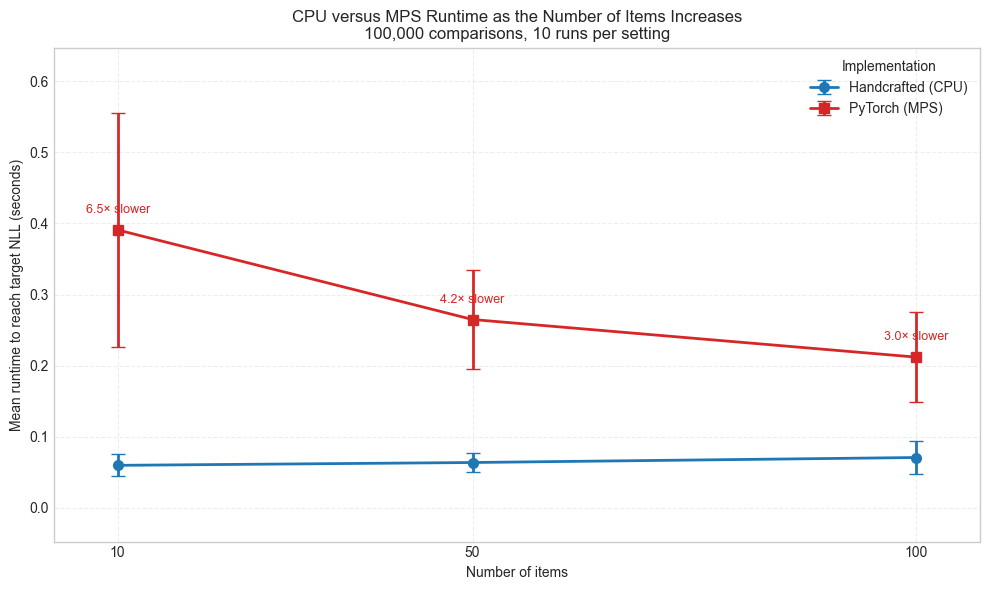

In [51]:
# Plot mean runtime against the number of items.

figure, axis = plt.subplots(
    figsize=(10, 6)
)

plot_styles = {
    "Handcrafted": {
        "color": "#1f77b4",
        "marker": "o",
    },
    "PyTorch": {
        "color": "#d62728",
        "marker": "s",
    },
}

for implementation in [
    "Handcrafted",
    "PyTorch",
]:
    implementation_data = (
        item_scaling_summary[
            item_scaling_summary["Implementation"]
            == implementation
        ]
        .sort_values("Number of items")
    )

    device = implementation_data[
        "Device"
    ].iloc[0]

    axis.errorbar(
        implementation_data["Number of items"],
        implementation_data["Mean_runtime"],
        yerr=implementation_data["Runtime_std"],
        label=f"{implementation} ({device})",
        color=plot_styles[implementation]["color"],
        marker=plot_styles[implementation]["marker"],
        markersize=7,
        linewidth=2,
        capsize=5,
    )

# Calculate the MPS-to-CPU runtime ratio.
runtime_pivot = item_scaling_summary.pivot(
    index="Number of items",
    columns="Implementation",
    values="Mean_runtime",
)

for number_of_items in runtime_pivot.index:
    cpu_runtime = runtime_pivot.loc[
        number_of_items,
        "Handcrafted",
    ]

    mps_runtime = runtime_pivot.loc[
        number_of_items,
        "PyTorch",
    ]

    runtime_ratio = mps_runtime / cpu_runtime

    axis.annotate(
        f"{runtime_ratio:.1f}× slower",
        xy=(number_of_items, mps_runtime),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#d62728",
    )

axis.set_xlabel("Number of items")
axis.set_ylabel(
    "Mean runtime to reach target NLL (seconds)"
)
axis.set_title(
    "CPU versus MPS Runtime as the Number of Items Increases\n"
    f"{FIXED_SCALING_COMPARISONS:,} comparisons, "
    f"{NUMBER_OF_SCALING_RUNS} runs per setting"
)

axis.set_xticks(SCALING_ITEM_COUNTS)
axis.legend(title="Implementation")
axis.grid(
    True,
    linestyle="--",
    alpha=0.35,
)
axis.margins(
    x=0.08,
    y=0.18,
)

plt.tight_layout()
plt.show()

### Supplementary Experiment: Optimization Without a Target NLL


In [54]:
# Run every optimizer using gradient convergence instead of a target NLL.

NO_TARGET_GRADIENT_TOLERANCE = 1e-4

zero_parameters = np.zeros(
    NUMBER_OF_ITEMS,
    dtype=float,
)

no_target_jobs = [
    (
        "Handcrafted",
        "Full-batch GD",
        NUMBER_OF_COMPARISONS,
        full_batch_learning_rate,
        lambda: optimize_with_full_batch_gradient_descent(
            number_of_items=NUMBER_OF_ITEMS,
            comparisons=comparisons,
            learning_rate=full_batch_learning_rate,
            gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
            target_nll=None,
        ),
    ),
    (
        "Handcrafted",
        "SGD",
        1,
        sgd_learning_rate,
        lambda: optimize_with_stochastic_gradient_descent(
            number_of_items=NUMBER_OF_ITEMS,
            comparisons=comparisons,
            learning_rate=sgd_learning_rate,
            random_seed=SEED,
            gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
            target_nll=None,
        ),
    ),
    (
        "Handcrafted",
        "Mini-batch GD",
        MINIBATCH_SIZE,
        minibatch_learning_rate,
        lambda: optimize_with_minibatch_gradient_descent(
            number_of_items=NUMBER_OF_ITEMS,
            comparisons=comparisons,
            learning_rate=minibatch_learning_rate,
            batch_size=MINIBATCH_SIZE,
            random_seed=SEED,
            gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
            target_nll=None,
        ),
    ),
    (
        "Handcrafted",
        "Momentum GD",
        MINIBATCH_SIZE,
        momentum_learning_rate,
        lambda: optimize_with_momentum_gradient_descent(
            number_of_items=NUMBER_OF_ITEMS,
            comparisons=comparisons,
            learning_rate=momentum_learning_rate,
            batch_size=MINIBATCH_SIZE,
            momentum=momentum_coefficient,
            random_seed=SEED,
            gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
            target_nll=None,
        ),
    ),
    (
        "Handcrafted",
        "Adam",
        MINIBATCH_SIZE,
        adam_learning_rate,
        lambda: optimize_with_adam(
            number_of_items=NUMBER_OF_ITEMS,
            comparisons=comparisons,
            learning_rate=adam_learning_rate,
            batch_size=MINIBATCH_SIZE,
            beta_1=adam_beta_1,
            beta_2=adam_beta_2,
            epsilon=adam_epsilon,
            random_seed=SEED,
            gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
            target_nll=None,
        ),
    ),
    (
        "PyTorch",
        "Full-batch GD",
        NUMBER_OF_COMPARISONS,
        PYTORCH_FULL_BATCH_LEARNING_RATE,
        lambda: (
            bt_torch.optimize_with_pytorch_full_batch_gradient_descent(
                number_of_items=NUMBER_OF_ITEMS,
                comparisons=comparisons,
                learning_rate=PYTORCH_FULL_BATCH_LEARNING_RATE,
                gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
                target_nll=None,
                initial_parameters=zero_parameters.copy(),
            )
        ),
    ),
    (
        "PyTorch",
        "SGD",
        1,
        PYTORCH_SGD_LEARNING_RATE,
        lambda: (
            bt_torch.optimize_with_pytorch_stochastic_gradient_descent(
                number_of_items=NUMBER_OF_ITEMS,
                comparisons=comparisons,
                learning_rate=PYTORCH_SGD_LEARNING_RATE,
                random_seed=SEED,
                gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
                target_nll=None,
                initial_parameters=zero_parameters.copy(),
            )
        ),
    ),
    (
        "PyTorch",
        "Mini-batch GD",
        MINIBATCH_SIZE,
        PYTORCH_MINIBATCH_LEARNING_RATE,
        lambda: (
            bt_torch.optimize_with_pytorch_minibatch_gradient_descent(
                number_of_items=NUMBER_OF_ITEMS,
                comparisons=comparisons,
                learning_rate=PYTORCH_MINIBATCH_LEARNING_RATE,
                batch_size=MINIBATCH_SIZE,
                random_seed=SEED,
                gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
                target_nll=None,
                initial_parameters=zero_parameters.copy(),
            )
        ),
    ),
    (
        "PyTorch",
        "Momentum GD",
        MINIBATCH_SIZE,
        PYTORCH_MOMENTUM_LEARNING_RATE,
        lambda: (
            bt_torch.optimize_with_pytorch_momentum_gradient_descent(
                number_of_items=NUMBER_OF_ITEMS,
                comparisons=comparisons,
                learning_rate=PYTORCH_MOMENTUM_LEARNING_RATE,
                batch_size=MINIBATCH_SIZE,
                momentum=PYTORCH_MOMENTUM_COEFFICIENT,
                random_seed=SEED,
                gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
                target_nll=None,
                initial_parameters=zero_parameters.copy(),
            )
        ),
    ),
    (
        "PyTorch",
        "Adam",
        MINIBATCH_SIZE,
        PYTORCH_ADAM_LEARNING_RATE,
        lambda: bt_torch.optimize_with_pytorch_adam(
            number_of_items=NUMBER_OF_ITEMS,
            comparisons=comparisons,
            learning_rate=PYTORCH_ADAM_LEARNING_RATE,
            batch_size=MINIBATCH_SIZE,
            beta_1=PYTORCH_ADAM_BETA_1,
            beta_2=PYTORCH_ADAM_BETA_2,
            epsilon=PYTORCH_ADAM_EPSILON,
            random_seed=SEED,
            gradient_tolerance=NO_TARGET_GRADIENT_TOLERANCE,
            target_nll=None,
            initial_parameters=zero_parameters.copy(),
        ),
    ),
]

In [55]:
# Execute the target-free convergence experiment.

no_target_results = []
no_target_rows = []

for (
    implementation,
    optimizer_name,
    batch_size,
    learning_rate,
    run_optimizer,
) in no_target_jobs:

    print(
        f"Running {implementation} "
        f"{optimizer_name}..."
    )

    result = run_optimizer()

    final_gradient_norm = float(
        result.gradient_norm_history[-1]
    )

    converged = (
        final_gradient_norm
        <= NO_TARGET_GRADIENT_TOLERANCE
    )

    no_target_results.append({
        "Implementation": implementation,
        "Optimizer": optimizer_name,
        "Result": result,
    })

    no_target_rows.append({
        "Implementation": implementation,
        "Optimizer": optimizer_name,
        "Learning rate": learning_rate,
        "Batch size": batch_size,
        "Final NLL": result.nll_history[-1],
        "Final gradient norm": final_gradient_norm,
        "Recovery RMSE": parameter_recovery_error(
            true_parameters,
            result.parameters,
        ),
        "Epochs": result.epochs_completed,
        "Parameter updates": int(
            result.update_count_history[-1]
        ),
        "Runtime (seconds)": result.runtime_seconds,
        "Converged": converged,
        "Stopping reason": result.stopping_reason,
    })

no_target_comparison_table = pd.DataFrame(
    no_target_rows
)

display(
    no_target_comparison_table.style.format({
        "Learning rate": "{:.4f}",
        "Batch size": "{:,}",
        "Final NLL": "{:.6f}",
        "Final gradient norm": "{:.4e}",
        "Recovery RMSE": "{:.4f}",
        "Epochs": "{:,}",
        "Parameter updates": "{:,}",
        "Runtime (seconds)": "{:.4f}",
    })
)

Running Handcrafted Full-batch GD...
Running Handcrafted SGD...
Running Handcrafted Mini-batch GD...
Running Handcrafted Momentum GD...
Running Handcrafted Adam...
Running PyTorch Full-batch GD...
Running PyTorch SGD...
Running PyTorch Mini-batch GD...
Running PyTorch Momentum GD...
Running PyTorch Adam...


,Implementation,Optimizer,Learning rate,Batch size,Final NLL,Final gradient norm,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Converged,Stopping reason
0,Handcrafted,Full-batch GD,0.1000,"10,000",0.598234,9.9812e-05,0.0381,"2,068","2,068",1.2043,True,gradient tolerance reached
1,Handcrafted,SGD,0.0010,1,0.598236,4.7973e-04,0.0393,"10,000","100,000,000",2890.2838,False,emergency maximum epochs reached
2,Handcrafted,Mini-batch GD,0.0100,128,0.598234,9.0002e-05,0.0384,743,"58,697",2.3831,True,gradient tolerance reached
3,Handcrafted,Momentum GD,0.0100,128,0.598240,7.9182e-04,0.0404,"10,000","790,000",32.2456,False,emergency maximum epochs reached
4,Handcrafted,Adam,0.0100,128,0.598302,2.4943e-03,0.0408,"10,000","790,000",35.5525,False,emergency maximum epochs reached
5,PyTorch,Full-batch GD,0.1000,"10,000",0.598234,9.9812e-05,0.0381,"2,068","2,068",1.6145,True,gradient tolerance reached
6,PyTorch,SGD,0.0010,1,0.598236,4.5376e-04,0.0395,"10,000","100,000,000",7479.2704,False,emergency maximum epochs reached
7,PyTorch,Mini-batch GD,0.0500,128,0.598238,6.3122e-04,0.0387,"10,000","790,000",66.2933,False,emergency maximum epochs reached
8,PyTorch,Momentum GD,0.0100,128,0.598245,9.8151e-04,0.0360,"10,000","790,000",69.1792,False,emergency maximum epochs reached
9,PyTorch,Adam,0.0100,128,0.598324,2.9118e-03,0.0438,"10,000","790,000",82.2791,False,emergency maximum epochs reached


(Plots for overleaf writing part..)

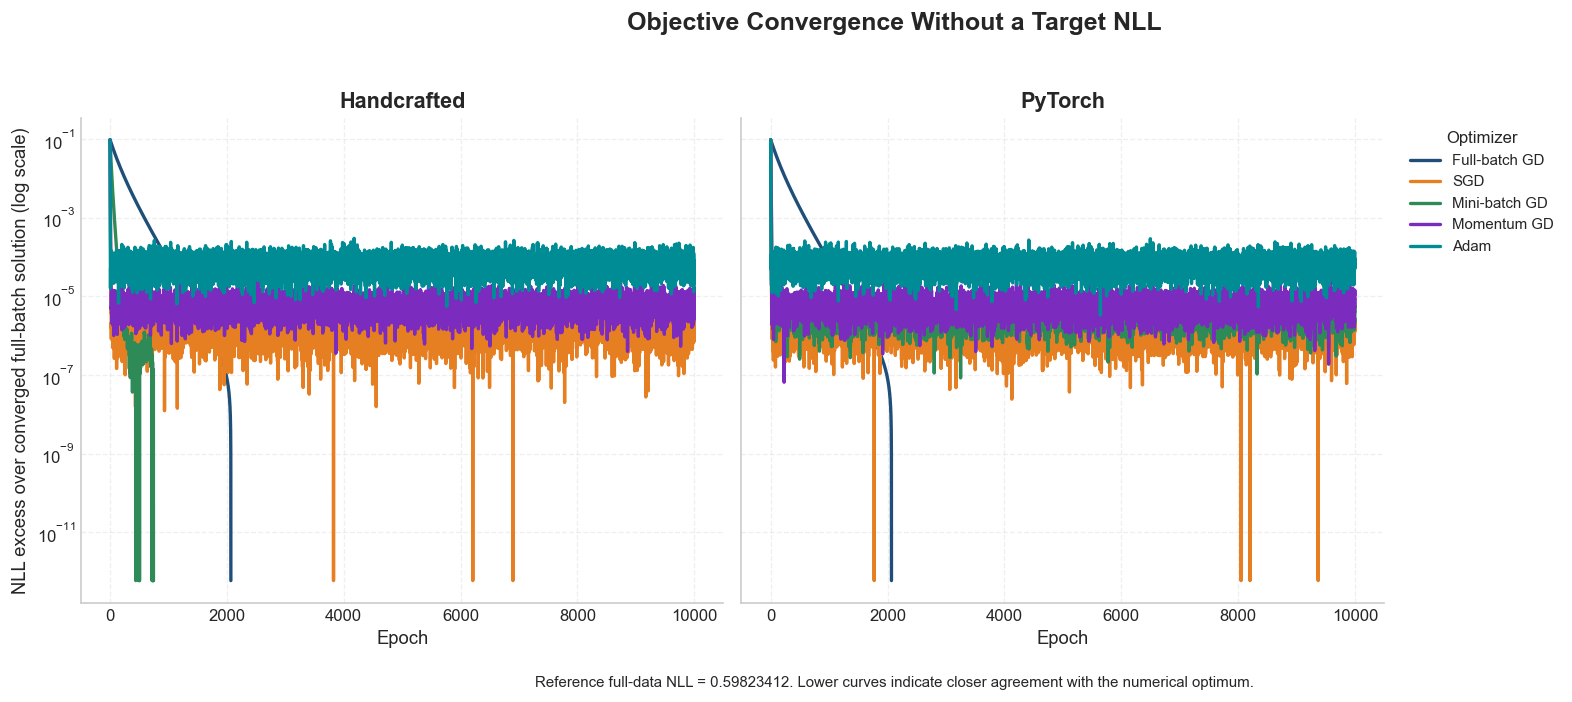

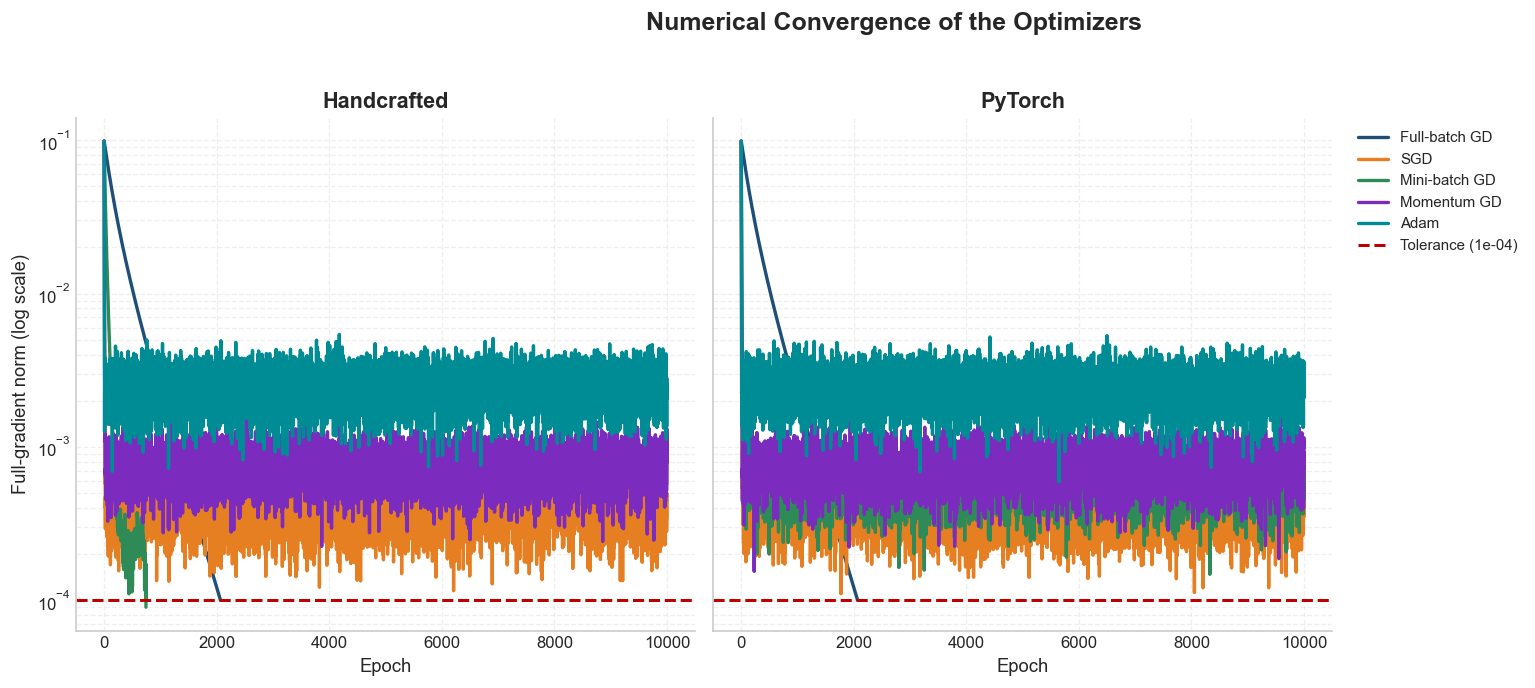

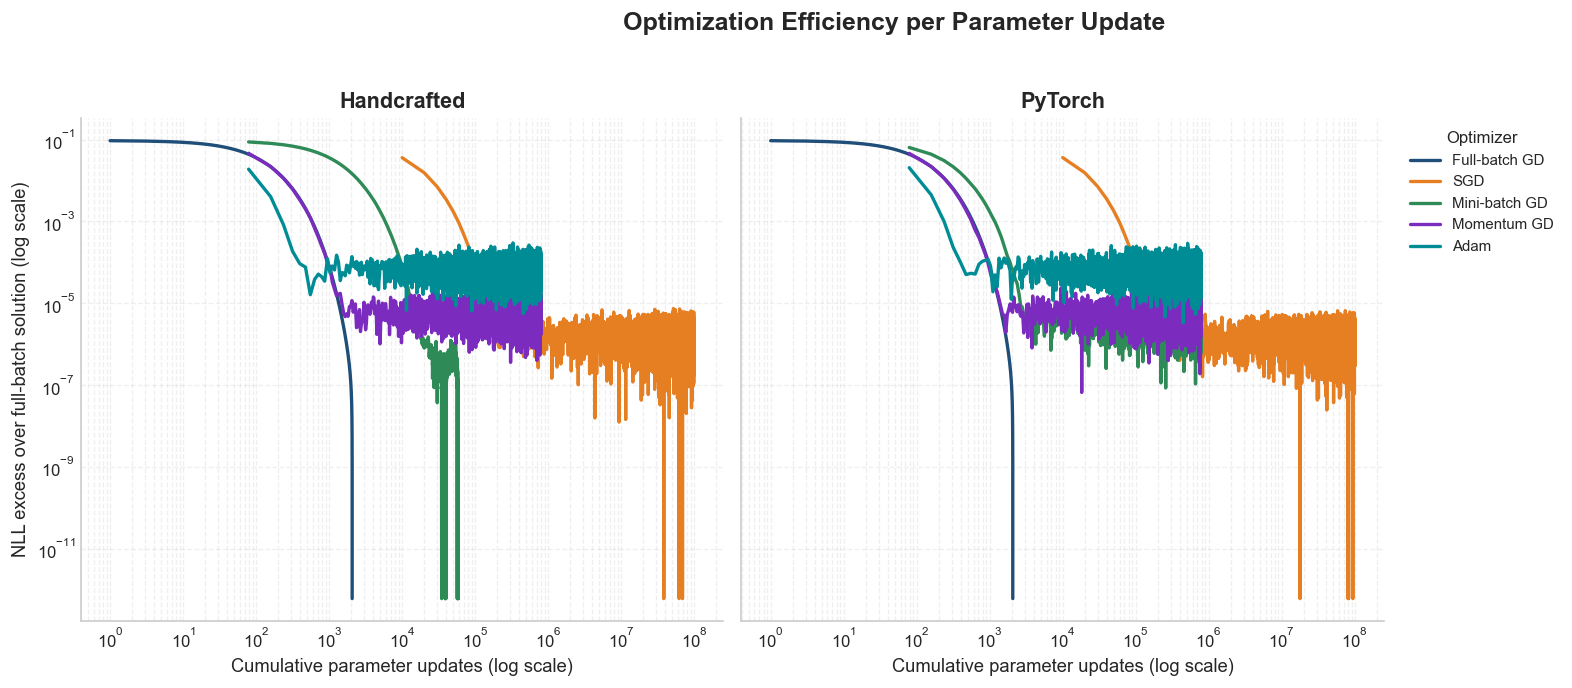

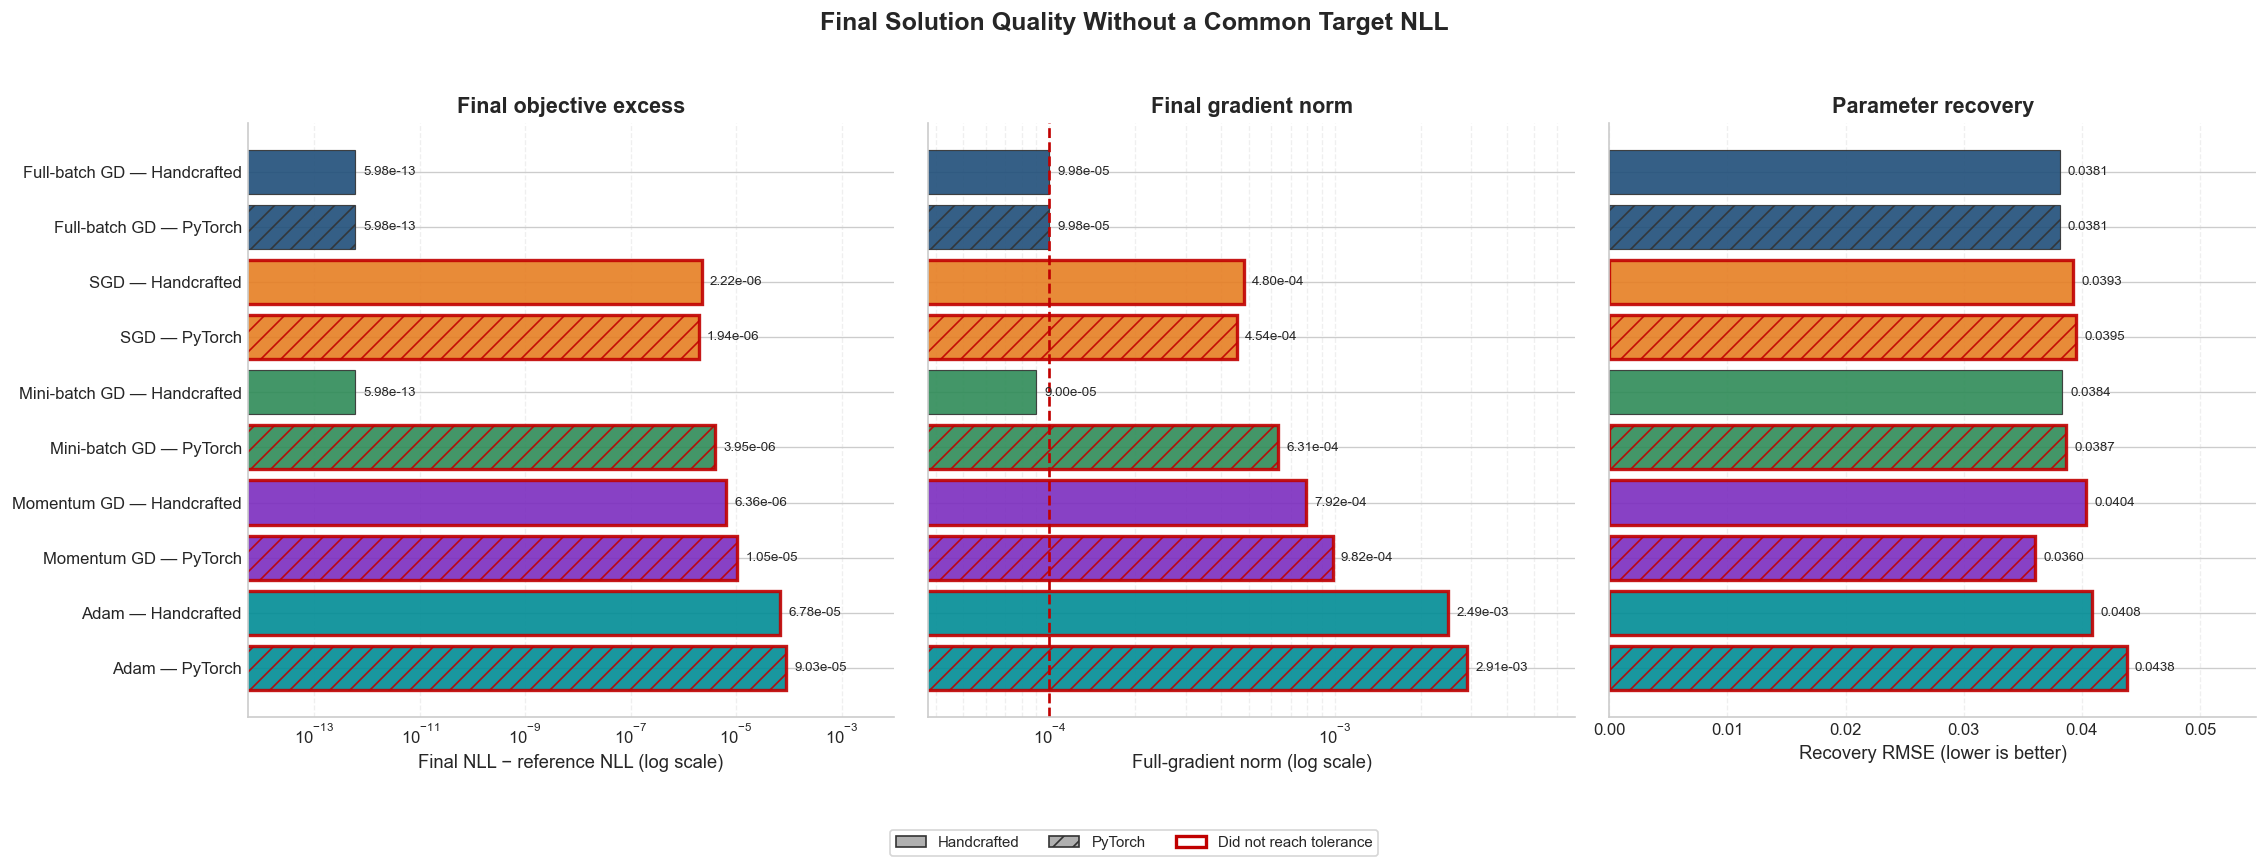

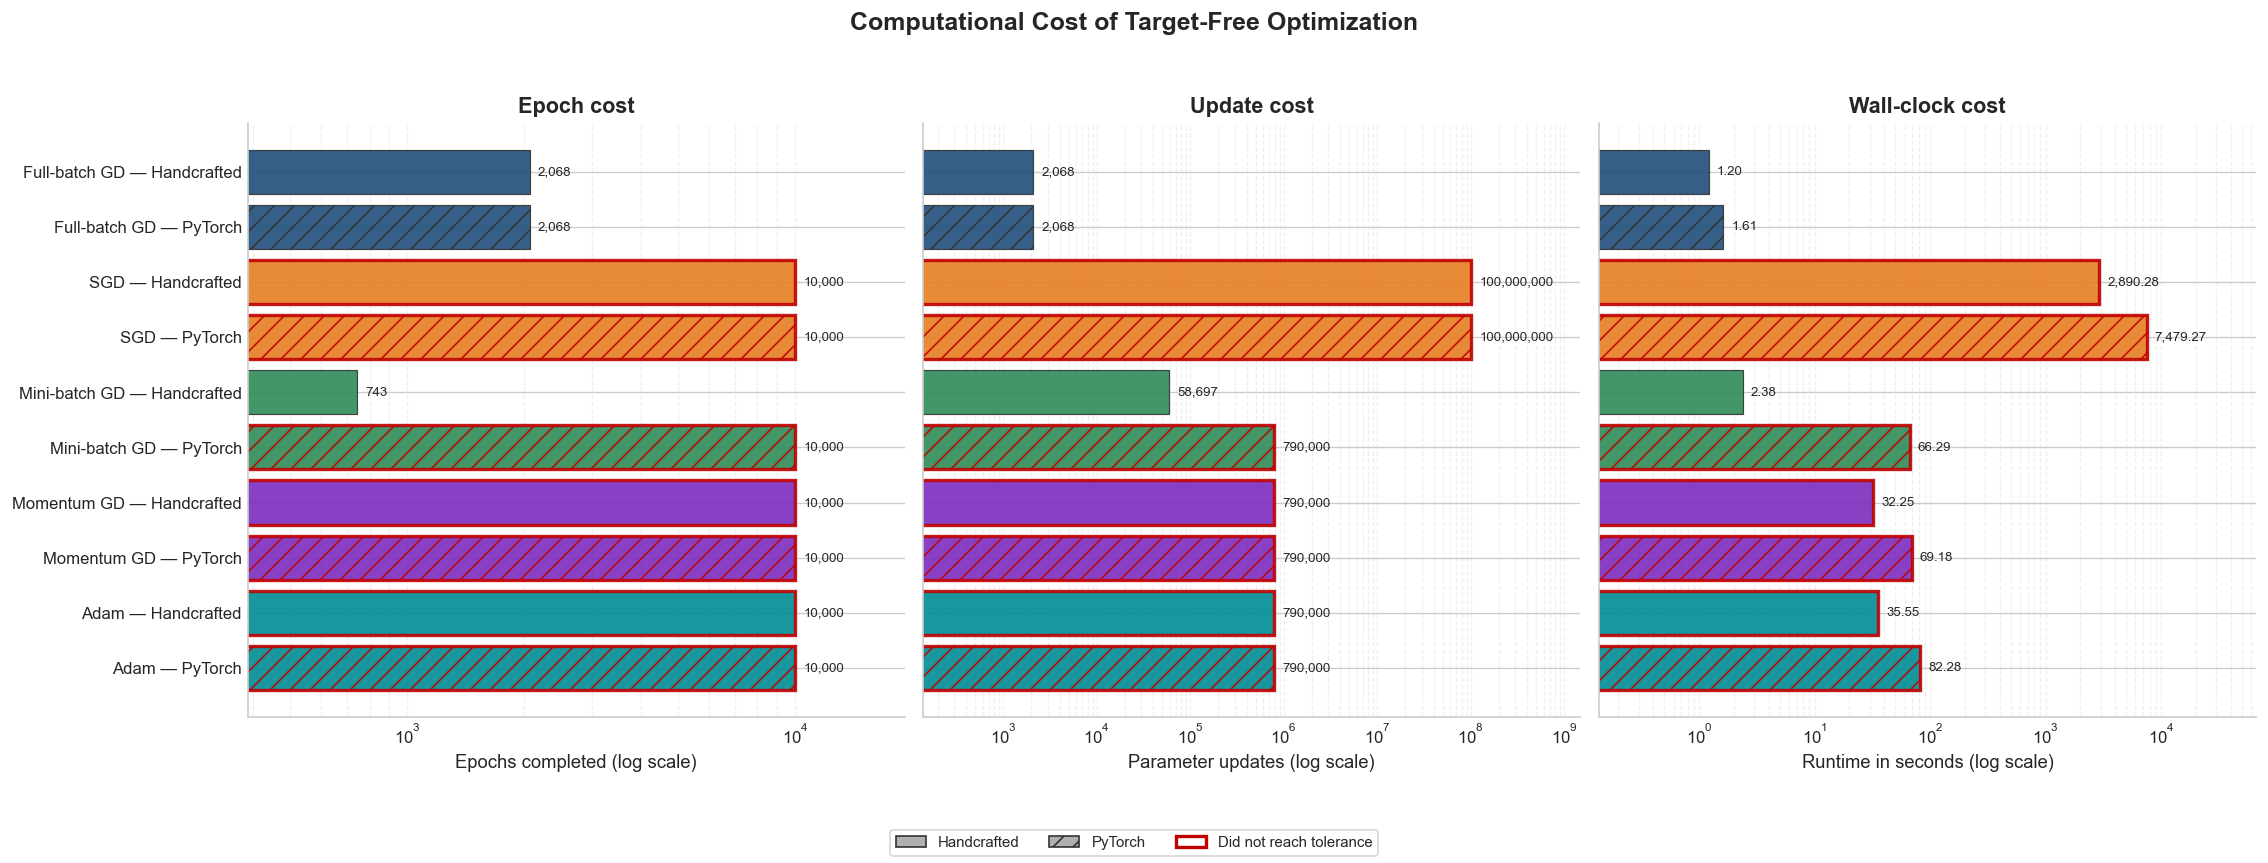

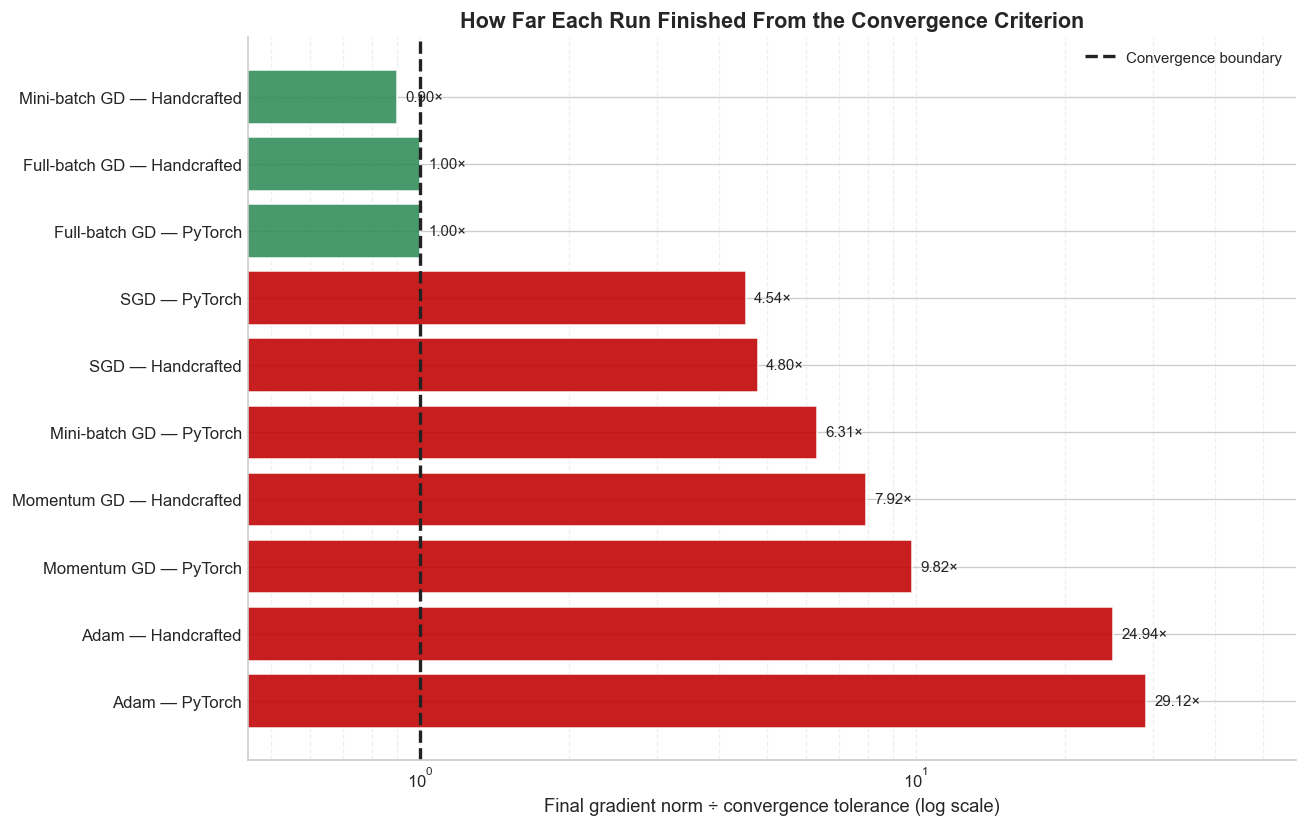

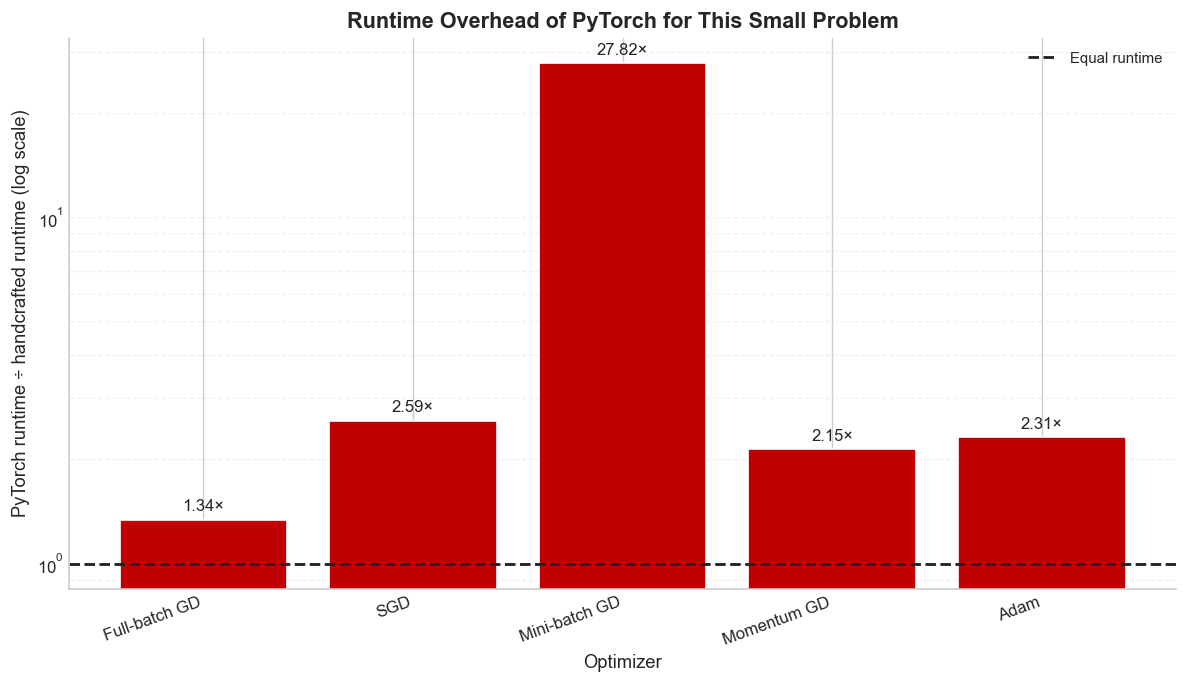

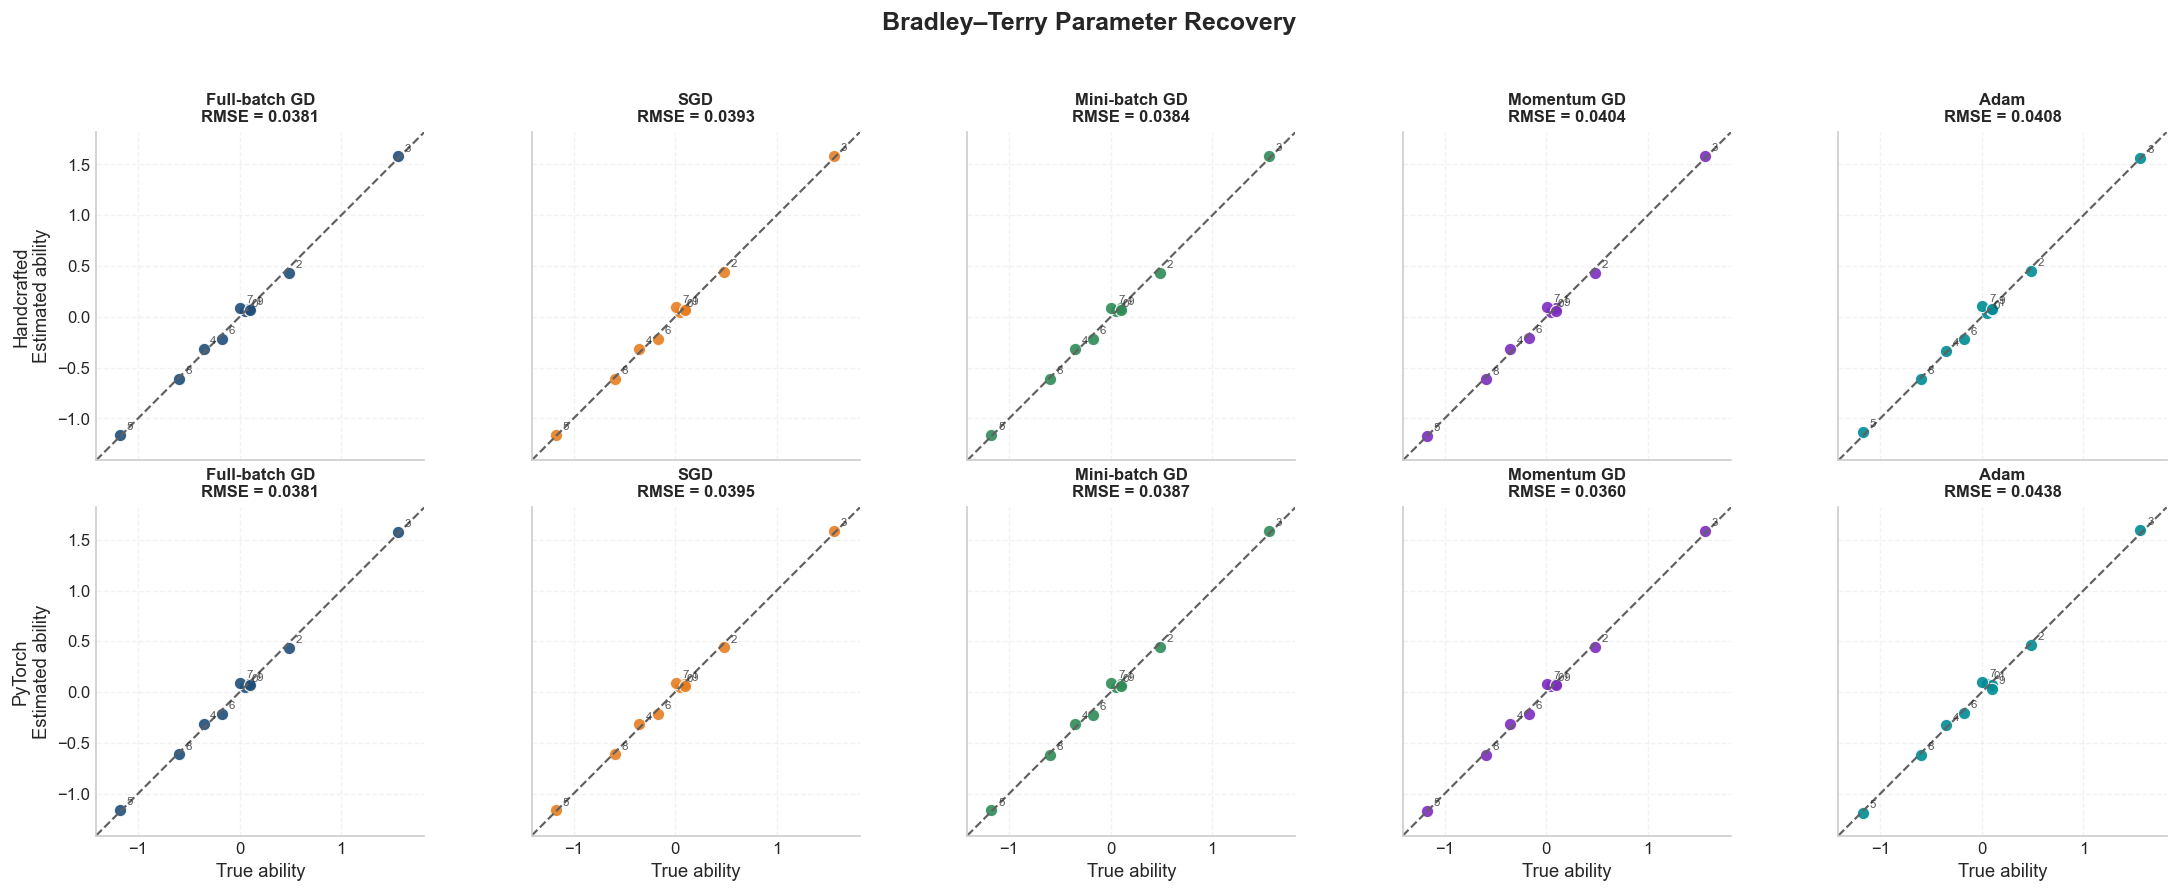

,Implementation,Optimizer,Final NLL,Final gradient norm,Gradient ratio,Recovery RMSE,Epochs,Parameter updates,Runtime (seconds),Converged
0,Handcrafted,Full-batch GD,0.59823412,9.9812e-05,1.00×,0.0381,"2,068","2,068",1.2043,True
1,PyTorch,Full-batch GD,0.59823412,9.9812e-05,1.00×,0.0381,"2,068","2,068",1.6145,True
2,Handcrafted,SGD,0.59823634,4.7973e-04,4.80×,0.0393,"10,000","100,000,000","2,890.2838",False
3,PyTorch,SGD,0.59823607,4.5376e-04,4.54×,0.0395,"10,000","100,000,000","7,479.2704",False
4,Handcrafted,Mini-batch GD,0.59823403,9.0002e-05,0.90×,0.0384,743,"58,697",2.3831,True
5,PyTorch,Mini-batch GD,0.59823807,6.3122e-04,6.31×,0.0387,"10,000","790,000",66.2933,False
6,Handcrafted,Momentum GD,0.59824048,7.9182e-04,7.92×,0.0404,"10,000","790,000",32.2456,False
7,PyTorch,Momentum GD,0.59824462,9.8151e-04,9.82×,0.0360,"10,000","790,000",69.1792,False
8,Handcrafted,Adam,0.59830197,2.4943e-03,24.94×,0.0408,"10,000","790,000",35.5525,False
9,PyTorch,Adam,0.59832439,2.9118e-03,29.12×,0.0438,"10,000","790,000",82.2791,False


Reference NLL: 0.5982341215
Figures and table saved in:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/notebooks/experiments/Bradley_Terry_Model/outputs/no_target_convergence
  - 01_nll_excess_vs_epoch.png
  - 01_nll_excess_vs_epoch.pdf
  - 02_gradient_norm_vs_epoch.png
  - 02_gradient_norm_vs_epoch.pdf
  - 03_nll_excess_vs_parameter_updates.png
  - 03_nll_excess_vs_parameter_updates.pdf
  - 04_final_solution_quality.png
  - 04_final_solution_quality.pdf
  - 05_computational_cost.png
  - 05_computational_cost.pdf
  - 06_distance_from_convergence.png
  - 06_distance_from_convergence.pdf
  - 07_pytorch_to_handcrafted_runtime_ratio.png
  - 07_pytorch_to_handcrafted_runtime_ratio.pdf
  - 08_parameter_recovery.png
  - 08_parameter_recovery.pdf


In [ ]:


from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


OUTPUT_DIRECTORY = Path(
    "outputs/no_target_convergence"
)

OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

OPTIMIZER_ORDER = [
    "Full-batch GD",
    "SGD",
    "Mini-batch GD",
    "Momentum GD",
    "Adam",
]

IMPLEMENTATION_ORDER = [
    "Handcrafted",
    "PyTorch",
]

OPTIMIZER_COLORS = {
    "Full-batch GD": "#1F4E79",
    "SGD": "#E67E22",
    "Mini-batch GD": "#2E8B57",
    "Momentum GD": "#7B2CBF",
    "Adam": "#008C95",
}

IMPLEMENTATION_HATCHES = {
    "Handcrafted": "",
    "PyTorch": "//",
}

CONVERGED_COLOR = "#2E8B57"
NOT_CONVERGED_COLOR = "#C00000"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


required_variables = [
    "no_target_results",
    "no_target_comparison_table",
    "NO_TARGET_GRADIENT_TOLERANCE",
    "true_parameters",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the target-free experiment first. "
        f"Missing variables: {missing_variables}"
    )

if len(no_target_results) == 0:
    raise RuntimeError(
        "no_target_results is empty."
    )

summary = no_target_comparison_table.copy()

summary["Implementation"] = pd.Categorical(
    summary["Implementation"],
    categories=IMPLEMENTATION_ORDER,
    ordered=True,
)

summary["Optimizer"] = pd.Categorical(
    summary["Optimizer"],
    categories=OPTIMIZER_ORDER,
    ordered=True,
)

summary = (
    summary
    .sort_values(
        ["Optimizer", "Implementation"]
    )
    .reset_index(drop=True)
)

summary["Converged"] = (
    summary["Converged"].astype(bool)
)

summary["Plot label"] = (
    summary["Optimizer"].astype(str)
    + " — "
    + summary["Implementation"].astype(str)
)

result_lookup = {
    (
        entry["Implementation"],
        entry["Optimizer"],
    ): entry["Result"]
    for entry in no_target_results
}


def as_numpy(value):
    """Convert NumPy arrays or PyTorch tensors to NumPy."""

    if hasattr(value, "detach"):
        value = value.detach()

    if hasattr(value, "cpu"):
        value = value.cpu()

    return np.asarray(
        value,
        dtype=float,
    )


# Use converged full-batch GD as the numerical optimum reference.
full_batch_reference_rows = summary[
    (summary["Optimizer"] == "Full-batch GD")
    & summary["Converged"]
]

if len(full_batch_reference_rows) > 0:
    reference_nll = float(
        full_batch_reference_rows[
            "Final NLL"
        ].mean()
    )
else:
    reference_nll = float(
        summary["Final NLL"].min()
    )

gap_floor = max(
    np.finfo(float).eps,
    abs(reference_nll) * 1e-12,
)

summary["Final NLL excess"] = np.maximum(
    summary["Final NLL"] - reference_nll,
    gap_floor,
)

summary["Gradient ratio"] = (
    summary["Final gradient norm"]
    / NO_TARGET_GRADIENT_TOLERANCE
)


saved_files = []


def save_and_show(figure, filename):
    """Save every figure in publication and preview formats."""

    png_path = OUTPUT_DIRECTORY / f"{filename}.png"
    pdf_path = OUTPUT_DIRECTORY / f"{filename}.pdf"

    figure.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    figure.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    saved_files.extend([
        png_path,
        pdf_path,
    ])

    plt.show()



figure, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.8),
    sharey=True,
)

for axis, implementation in zip(
    axes,
    IMPLEMENTATION_ORDER,
):
    for optimizer in OPTIMIZER_ORDER:
        key = (
            implementation,
            optimizer,
        )

        if key not in result_lookup:
            continue

        result = result_lookup[key]

        nll_history = as_numpy(
            result.nll_history
        )

        epochs = np.arange(
            len(nll_history)
        )

        nll_excess = np.maximum(
            nll_history - reference_nll,
            gap_floor,
        )

        axis.semilogy(
            epochs,
            nll_excess,
            color=OPTIMIZER_COLORS[optimizer],
            linewidth=2,
            label=optimizer,
        )

    axis.set_title(implementation)
    axis.set_xlabel("Epoch")
    axis.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.3,
    )

axes[0].set_ylabel(
    "NLL excess over converged full-batch solution "
    "(log scale)"
)

axes[1].legend(
    title="Optimizer",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

figure.suptitle(
    "Objective Convergence Without a Target NLL",
    fontsize=15,
    fontweight="bold",
)

figure.text(
    0.5,
    0.01,
    (
        f"Reference full-data NLL = {reference_nll:.8f}. "
        "Lower curves indicate closer agreement with the numerical optimum."
    ),
    ha="center",
    fontsize=9,
)

plt.tight_layout(
    rect=[0, 0.04, 0.88, 0.95]
)

save_and_show(
    figure,
    "01_nll_excess_vs_epoch",
)


figure, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.8),
    sharey=True,
)

for axis, implementation in zip(
    axes,
    IMPLEMENTATION_ORDER,
):
    for optimizer in OPTIMIZER_ORDER:
        key = (
            implementation,
            optimizer,
        )

        if key not in result_lookup:
            continue

        result = result_lookup[key]

        gradient_history = as_numpy(
            result.gradient_norm_history
        )

        epochs = np.arange(
            len(gradient_history)
        )

        axis.semilogy(
            epochs,
            np.maximum(
                gradient_history,
                np.finfo(float).tiny,
            ),
            color=OPTIMIZER_COLORS[optimizer],
            linewidth=2,
            label=optimizer,
        )

    axis.axhline(
        NO_TARGET_GRADIENT_TOLERANCE,
        color=NOT_CONVERGED_COLOR,
        linestyle="--",
        linewidth=1.8,
        label=(
            "Tolerance "
            f"({NO_TARGET_GRADIENT_TOLERANCE:.0e})"
        ),
    )

    axis.set_title(implementation)
    axis.set_xlabel("Epoch")
    axis.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.3,
    )

axes[0].set_ylabel(
    "Full-gradient norm (log scale)"
)

handles, labels = axes[1].get_legend_handles_labels()

# Remove repeated tolerance labels.
unique_legend = dict(zip(labels, handles))

axes[1].legend(
    unique_legend.values(),
    unique_legend.keys(),
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

figure.suptitle(
    "Numerical Convergence of the Optimizers",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0, 0.86, 0.95]
)

save_and_show(
    figure,
    "02_gradient_norm_vs_epoch",
)


figure, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.8),
    sharey=True,
)

for axis, implementation in zip(
    axes,
    IMPLEMENTATION_ORDER,
):
    for optimizer in OPTIMIZER_ORDER:
        key = (
            implementation,
            optimizer,
        )

        if key not in result_lookup:
            continue

        result = result_lookup[key]

        updates = as_numpy(
            result.update_count_history
        )

        nll_history = as_numpy(
            result.nll_history
        )

        usable_length = min(
            len(updates),
            len(nll_history),
        )

        updates = updates[:usable_length]
        nll_history = nll_history[:usable_length]

        valid = updates > 0

        nll_excess = np.maximum(
            nll_history[valid] - reference_nll,
            gap_floor,
        )

        axis.loglog(
            updates[valid],
            nll_excess,
            color=OPTIMIZER_COLORS[optimizer],
            linewidth=2,
            label=optimizer,
        )

    axis.set_title(implementation)
    axis.set_xlabel(
        "Cumulative parameter updates (log scale)"
    )
    axis.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.3,
    )

axes[0].set_ylabel(
    "NLL excess over full-batch solution "
    "(log scale)"
)

axes[1].legend(
    title="Optimizer",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

figure.suptitle(
    "Optimization Efficiency per Parameter Update",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0, 0.88, 0.95]
)

save_and_show(
    figure,
    "03_nll_excess_vs_parameter_updates",
)


def draw_metric_panel(
    axis,
    data,
    metric,
    title,
    xlabel,
    logarithmic=False,
    formatter="{:.2e}",
    reference_value=None,
):
    positions = np.arange(
        len(data)
    )

    values = data[metric].to_numpy(
        dtype=float
    )

    if logarithmic:
        plotted_values = np.maximum(
            values,
            np.finfo(float).tiny,
        )
    else:
        plotted_values = values

    colors = [
        OPTIMIZER_COLORS[str(optimizer)]
        for optimizer in data["Optimizer"]
    ]

    edge_colors = [
        "#333333" if converged
        else NOT_CONVERGED_COLOR
        for converged in data["Converged"]
    ]

    line_widths = [
        0.7 if converged else 2.0
        for converged in data["Converged"]
    ]

    bars = axis.barh(
        positions,
        plotted_values,
        color=colors,
        edgecolor=edge_colors,
        linewidth=line_widths,
        alpha=0.9,
    )

    for bar, implementation in zip(
        bars,
        data["Implementation"],
    ):
        bar.set_hatch(
            IMPLEMENTATION_HATCHES[
                str(implementation)
            ]
        )

    for position, value in zip(
        positions,
        plotted_values,
    ):
        axis.annotate(
            formatter.format(value),
            xy=(value, position),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
        )

    if logarithmic:
        axis.set_xscale("log")

    if reference_value is not None:
        axis.axvline(
            reference_value,
            color=NOT_CONVERGED_COLOR,
            linestyle="--",
            linewidth=1.6,
        )

    axis.set_title(title)
    axis.set_xlabel(xlabel)
    axis.set_yticks(positions)
    axis.set_yticklabels(
        data["Plot label"]
    )
    axis.invert_yaxis()
    axis.grid(
        True,
        axis="x",
        which="both",
        linestyle="--",
        alpha=0.3,
    )
    axis.margins(x=0.25)



figure, axes = plt.subplots(
    1,
    3,
    figsize=(19, 7.2),
    sharey=True,
)

draw_metric_panel(
    axes[0],
    summary,
    "Final NLL excess",
    "Final objective excess",
    "Final NLL − reference NLL (log scale)",
    logarithmic=True,
    formatter="{:.2e}",
)

draw_metric_panel(
    axes[1],
    summary,
    "Final gradient norm",
    "Final gradient norm",
    "Full-gradient norm (log scale)",
    logarithmic=True,
    formatter="{:.2e}",
    reference_value=NO_TARGET_GRADIENT_TOLERANCE,
)

draw_metric_panel(
    axes[2],
    summary,
    "Recovery RMSE",
    "Parameter recovery",
    "Recovery RMSE (lower is better)",
    logarithmic=False,
    formatter="{:.4f}",
)

axes[1].tick_params(labelleft=False)
axes[2].tick_params(labelleft=False)

legend_handles = [
    Patch(
        facecolor="#B0B0B0",
        edgecolor="#333333",
        label="Handcrafted",
    ),
    Patch(
        facecolor="#B0B0B0",
        edgecolor="#333333",
        hatch="//",
        label="PyTorch",
    ),
    Patch(
        facecolor="white",
        edgecolor=NOT_CONVERGED_COLOR,
        linewidth=2,
        label="Did not reach tolerance",
    ),
]

figure.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    frameon=True,
)

figure.suptitle(
    "Final Solution Quality Without a Common Target NLL",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0.08, 1, 0.95]
)

save_and_show(
    figure,
    "04_final_solution_quality",
)



figure, axes = plt.subplots(
    1,
    3,
    figsize=(19, 7.2),
    sharey=True,
)

draw_metric_panel(
    axes[0],
    summary,
    "Epochs",
    "Epoch cost",
    "Epochs completed (log scale)",
    logarithmic=True,
    formatter="{:,.0f}",
)

draw_metric_panel(
    axes[1],
    summary,
    "Parameter updates",
    "Update cost",
    "Parameter updates (log scale)",
    logarithmic=True,
    formatter="{:,.0f}",
)

draw_metric_panel(
    axes[2],
    summary,
    "Runtime (seconds)",
    "Wall-clock cost",
    "Runtime in seconds (log scale)",
    logarithmic=True,
    formatter="{:,.2f}",
)

axes[1].tick_params(labelleft=False)
axes[2].tick_params(labelleft=False)

figure.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    frameon=True,
)

figure.suptitle(
    "Computational Cost of Target-Free Optimization",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0.08, 1, 0.95]
)

save_and_show(
    figure,
    "05_computational_cost",
)

convergence_data = (
    summary
    .sort_values(
        "Gradient ratio",
        ascending=True,
    )
    .reset_index(drop=True)
)

positions = np.arange(
    len(convergence_data)
)

gradient_ratios = convergence_data[
    "Gradient ratio"
].to_numpy(dtype=float)

status_colors = [
    CONVERGED_COLOR if converged
    else NOT_CONVERGED_COLOR
    for converged in convergence_data[
        "Converged"
    ]
]

figure, axis = plt.subplots(
    figsize=(11, 7)
)

bars = axis.barh(
    positions,
    gradient_ratios,
    color=status_colors,
    edgecolor="white",
    alpha=0.88,
)

axis.axvline(
    1.0,
    color="#222222",
    linestyle="--",
    linewidth=2,
    label="Convergence boundary",
)

axis.set_xscale("log")
axis.set_yticks(positions)
axis.set_yticklabels(
    convergence_data["Plot label"]
)
axis.invert_yaxis()

for position, ratio in zip(
    positions,
    gradient_ratios,
):
    axis.annotate(
        f"{ratio:.2f}×",
        xy=(ratio, position),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

axis.set_xlabel(
    "Final gradient norm ÷ convergence tolerance "
    "(log scale)"
)

axis.set_ylabel("")

axis.set_title(
    "How Far Each Run Finished From the Convergence Criterion"
)

axis.grid(
    True,
    axis="x",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.legend()

axis.margins(x=0.2)

plt.tight_layout()

save_and_show(
    figure,
    "06_distance_from_convergence",
)



runtime_pivot = (
    summary
    .pivot(
        index="Optimizer",
        columns="Implementation",
        values="Runtime (seconds)",
    )
    .reindex(OPTIMIZER_ORDER)
)

available_runtime_rows = (
    runtime_pivot
    .dropna(
        subset=[
            "Handcrafted",
            "PyTorch",
        ]
    )
    .copy()
)

available_runtime_rows["Runtime ratio"] = (
    available_runtime_rows["PyTorch"]
    / available_runtime_rows["Handcrafted"]
)

runtime_ratios = available_runtime_rows[
    "Runtime ratio"
]

ratio_colors = [
    NOT_CONVERGED_COLOR if ratio > 1
    else CONVERGED_COLOR
    for ratio in runtime_ratios
]

figure, axis = plt.subplots(
    figsize=(10, 5.8)
)

bars = axis.bar(
    available_runtime_rows.index,
    runtime_ratios,
    color=ratio_colors,
    edgecolor="white",
)

axis.axhline(
    1.0,
    color="#222222",
    linestyle="--",
    linewidth=1.7,
    label="Equal runtime",
)

for bar, ratio in zip(
    bars,
    runtime_ratios,
):
    axis.annotate(
        f"{ratio:.2f}×",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            ratio,
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
    )

axis.set_yscale("log")

axis.set_xlabel("Optimizer")

axis.set_ylabel(
    "PyTorch runtime ÷ handcrafted runtime "
    "(log scale)"
)

axis.set_title(
    "Runtime Overhead of PyTorch for This Small Problem"
)

axis.grid(
    True,
    axis="y",
    which="both",
    linestyle="--",
    alpha=0.3,
)

axis.legend()

plt.xticks(
    rotation=20,
    ha="right",
)

plt.tight_layout()

save_and_show(
    figure,
    "07_pytorch_to_handcrafted_runtime_ratio",
)



true_values = as_numpy(
    true_parameters
).reshape(-1)

# Center because Bradley–Terry abilities are identifiable
# only up to a common additive constant.
true_values = (
    true_values - true_values.mean()
)

all_parameter_values = [
    true_values
]

for result in result_lookup.values():
    estimated = as_numpy(
        result.parameters
    ).reshape(-1)

    estimated = (
        estimated - estimated.mean()
    )

    all_parameter_values.append(
        estimated
    )

parameter_minimum = min(
    values.min()
    for values in all_parameter_values
)

parameter_maximum = max(
    values.max()
    for values in all_parameter_values
)

parameter_padding = (
    0.08
    * (parameter_maximum - parameter_minimum)
)

plot_minimum = (
    parameter_minimum - parameter_padding
)

plot_maximum = (
    parameter_maximum + parameter_padding
)

figure, axes = plt.subplots(
    2,
    5,
    figsize=(19, 7.5),
    sharex=True,
    sharey=True,
)

for row_index, implementation in enumerate(
    IMPLEMENTATION_ORDER
):
    for column_index, optimizer in enumerate(
        OPTIMIZER_ORDER
    ):
        axis = axes[
            row_index,
            column_index,
        ]

        key = (
            implementation,
            optimizer,
        )

        if key not in result_lookup:
            axis.set_visible(False)
            continue

        result = result_lookup[key]

        estimated_values = as_numpy(
            result.parameters
        ).reshape(-1)

        estimated_values = (
            estimated_values
            - estimated_values.mean()
        )

        recovery_rmse = float(
            np.sqrt(
                np.mean(
                    (
                        estimated_values
                        - true_values
                    ) ** 2
                )
            )
        )

        axis.plot(
            [
                plot_minimum,
                plot_maximum,
            ],
            [
                plot_minimum,
                plot_maximum,
            ],
            color="#606060",
            linestyle="--",
            linewidth=1.3,
            label="Perfect recovery",
        )

        axis.scatter(
            true_values,
            estimated_values,
            color=OPTIMIZER_COLORS[optimizer],
            edgecolor="white",
            linewidth=0.7,
            s=55,
            alpha=0.9,
        )

        for item_index, (
            true_value,
            estimated_value,
        ) in enumerate(
            zip(
                true_values,
                estimated_values,
            )
        ):
            axis.annotate(
                str(item_index),
                xy=(
                    true_value,
                    estimated_value,
                ),
                xytext=(4, 3),
                textcoords="offset points",
                fontsize=7,
                alpha=0.75,
            )

        axis.set_xlim(
            plot_minimum,
            plot_maximum,
        )

        axis.set_ylim(
            plot_minimum,
            plot_maximum,
        )

        axis.set_aspect(
            "equal",
            adjustable="box",
        )

        axis.set_title(
            f"{optimizer}\nRMSE = {recovery_rmse:.4f}",
            fontsize=10,
        )

        axis.grid(
            True,
            linestyle="--",
            alpha=0.25,
        )

        if column_index == 0:
            axis.set_ylabel(
                f"{implementation}\nEstimated ability"
            )

        if row_index == 1:
            axis.set_xlabel(
                "True ability"
            )

figure.suptitle(
    "Bradley–Terry Parameter Recovery",
    fontsize=15,
    fontweight="bold",
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

save_and_show(
    figure,
    "08_parameter_recovery",
)


summary_output = summary.copy()

summary_output[
    "Implementation"
] = summary_output[
    "Implementation"
].astype(str)

summary_output[
    "Optimizer"
] = summary_output[
    "Optimizer"
].astype(str)

summary_output.to_csv(
    OUTPUT_DIRECTORY
    / "no_target_convergence_summary.csv",
    index=False,
)


thesis_summary = summary_output[
    [
        "Implementation",
        "Optimizer",
        "Final NLL",
        "Final gradient norm",
        "Gradient ratio",
        "Recovery RMSE",
        "Epochs",
        "Parameter updates",
        "Runtime (seconds)",
        "Converged",
    ]
].copy()

display(
    thesis_summary.style.format({
        "Final NLL": "{:.8f}",
        "Final gradient norm": "{:.4e}",
        "Gradient ratio": "{:.2f}×",
        "Recovery RMSE": "{:.4f}",
        "Epochs": "{:,.0f}",
        "Parameter updates": "{:,.0f}",
        "Runtime (seconds)": "{:,.4f}",
    }).map(
        lambda value: (
            "background-color: #D9EAD3; "
            "color: #1B5E20;"
            if value is True
            else (
                "background-color: #F4CCCC; "
                "color: #990000;"
                if value is False
                else ""
            )
        ),
        subset=["Converged"],
    )
)

print(
    f"Reference NLL: {reference_nll:.10f}"
)

print(
    "Figures and table saved in:"
)

print(
    OUTPUT_DIRECTORY.resolve()
)

for saved_file in saved_files:
    print(
        f"  - {saved_file.name}"
    )

As, we can see that the runtime for pytorch even via mps is higher than the handcrafted cpu optimizers, let us try after increasing some workloads, i.e. increading items to 100 and going with large comparison counts and large number of run with large batch sizes